# 🫀 Exercise: Heart Disease Prediction Using Machine Learning and PCA

| | |
|---|---|
| **Dataset** | Heart Failure Prediction Dataset |
| **Source** | [Kaggle – Heart Failure Prediction](https://www.kaggle.com/fedesoriano/heart-failure-prediction) |
| **File name** | `heart.csv` |
| **Folder** | `Exercise` |

**Student Name:** _Mohammed Affan Khan  &nbsp;&nbsp; **Roll No.:** 1RUA25CSE0265_ &nbsp;&nbsp; **Date:** 06-11-2006

---

## Problem Statement

Download the `heart.csv` dataset from Kaggle and save it in the `Exercise` folder. Perform data preprocessing, model building, hyperparameter tuning and dimensionality reduction to predict whether a patient has heart disease (`HeartDisease` = 1) or not (`HeartDisease` = 0).

### Instructions
- Write your code in the **empty code cells** provided below each task.
- Write your explanations in the **✍️ Your answer** cells.
- Run all cells from top to bottom before submitting (**Kernel → Restart & Run All**).
- Use `random_state=42` wherever randomness is involved so that results are reproducible.

## Overall Workflow

You will build the pipeline below. Path A trains models on all preprocessed features; Path B trains the same models on PCA-reduced features. Step 9 compares the two.

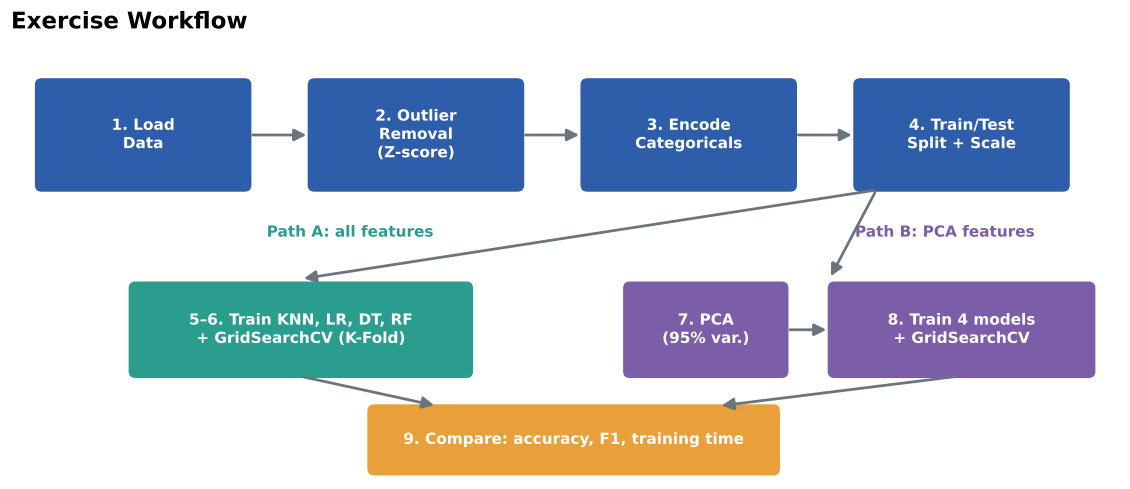

## Data Dictionary

| Feature | Description | Type |
|---|---|---|
| `Age` | Age of the patient (years) | Numerical |
| `Sex` | Sex of the patient (`M`, `F`) | Categorical (binary) |
| `ChestPainType` | `TA` typical angina, `ATA` atypical angina, `NAP` non-anginal pain, `ASY` asymptomatic | Categorical (nominal) |
| `RestingBP` | Resting blood pressure (mm Hg) | Numerical |
| `Cholesterol` | Serum cholesterol (mg/dl) | Numerical |
| `FastingBS` | Fasting blood sugar > 120 mg/dl (1 = yes, 0 = no) | Binary (already numeric) |
| `RestingECG` | Resting ECG result (`Normal`, `ST`, `LVH`) | Categorical (nominal) |
| `MaxHR` | Maximum heart rate achieved | Numerical |
| `ExerciseAngina` | Exercise-induced angina (`Y`, `N`) | Categorical (binary) |
| `Oldpeak` | ST depression induced by exercise | Numerical |
| `ST_Slope` | Slope of the peak exercise ST segment (`Up`, `Flat`, `Down`) | Categorical |
| `HeartDisease` | **Target** — 1 = heart disease, 0 = normal | Binary |

## Import Libraries

Import all the libraries you will need (pandas, numpy, matplotlib/seaborn, scipy, scikit-learn modules, `time`, etc.).

In [2]:
# Write your code here
# Data manipulation and numerical calculations
import pandas as pd
import numpy as np

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Z-score calculation
from scipy.stats import zscore

# Dataset splitting and feature scaling
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# PCA
from sklearn.decomposition import PCA

# Machine learning models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Training time calculation
import time

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

# Set visualisation style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


---
## Task 1: Load the Dataset

1. Load `Exercise/heart.csv` into a Pandas DataFrame.
2. Display the first five records.
3. Examine the dataset's **dimensions**, **column names**, **data types** and **missing values**.

### 1.1 Load the dataset and display the first five records

In [5]:
# Write your code here
# Load the heart disease dataset
df = pd.read_csv("heart - heart.csv")

# Display the first five records
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


### 1.2 Dimensions, column names and data types

In [6]:
# Write your code here
# Display the number of rows and columns
print("Dataset Dimensions:", df.shape)

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Dimensions: (918, 12)
Number of Rows: 918
Number of Columns: 12


### 1.3 Check for missing values

In [7]:
# Write your code here
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Total Missing Values:
0


### 1.4 (Optional) Class balance
Check how many records belong to each class of `HeartDisease`. Is the dataset balanced?

CLASS DISTRIBUTION
------------------
No Heart Disease (Class 0): 410 records
Percentage: 44.66%

Heart Disease (Class 1): 508 records
Percentage: 55.34%

CLASS BALANCE ANALYSIS
----------------------
Difference Between Classes: 98
Majority-to-Minority Ratio: 1.24
Dataset Status: Relatively Balanced


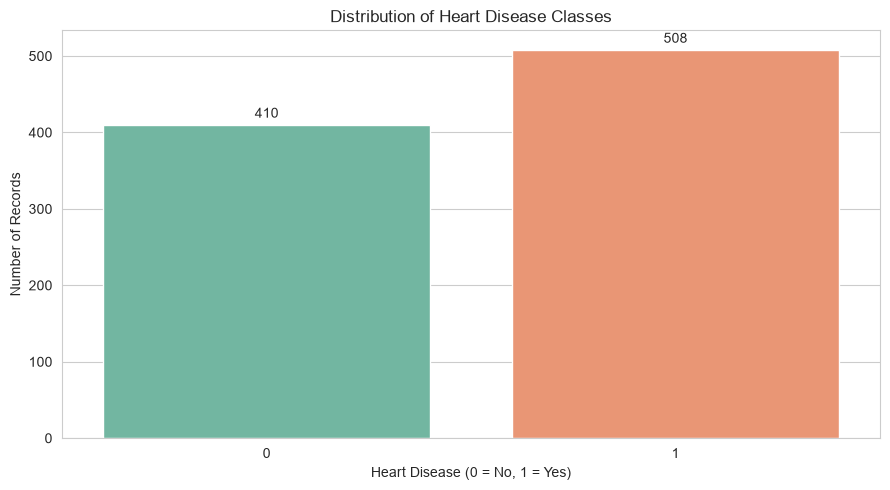


OBSERVATION
-----------
The dataset is relatively balanced.
Both classes have a reasonably similar number of records.


In [8]:
# Write your code here
# ---------------------------------------------------------
# TASK 1.4: CLASS BALANCE ANALYSIS
# ---------------------------------------------------------

# Count the number of records belonging to each class
class_counts = df["HeartDisease"].value_counts().sort_index()

# Calculate the percentage of records in each class
class_percentages = df["HeartDisease"].value_counts(
    normalize=True
).sort_index() * 100

# Display the class distribution
print("CLASS DISTRIBUTION")
print("------------------")

for class_label, count in class_counts.items():

    # Display class label, count and percentage
    class_name = "No Heart Disease" if class_label == 0 else "Heart Disease"

    print(f"{class_name} (Class {class_label}): {count} records")
    print(f"Percentage: {class_percentages[class_label]:.2f}%")
    print()

# Calculate the difference between the two class counts
class_difference = abs(class_counts.iloc[0] - class_counts.iloc[1])

# Calculate the ratio between the majority and minority classes
class_ratio = class_counts.max() / class_counts.min()

# Determine whether the dataset is balanced
if class_ratio <= 1.5:
    balance_status = "Relatively Balanced"
else:
    balance_status = "Imbalanced"

# Display the overall class balance
print("CLASS BALANCE ANALYSIS")
print("----------------------")
print("Difference Between Classes:", class_difference)
print("Majority-to-Minority Ratio:", round(class_ratio, 2))
print("Dataset Status:", balance_status)

# Visualise the number of records in each class
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df,
    x="HeartDisease",
    hue="HeartDisease",
    palette="Set2",
    legend=False
)

# Add count labels above each bar
for container in ax.containers:
    ax.bar_label(container, padding=3)

# Add chart title and axis labels
plt.title("Distribution of Heart Disease Classes")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

# Display final observation
print("\nOBSERVATION")
print("-----------")

if balance_status == "Relatively Balanced":
    print("The dataset is relatively balanced.")
    print("Both classes have a reasonably similar number of records.")
else:
    print("The dataset is imbalanced.")
    print("One class has considerably more records than the other.")

**Q1.** Summarise your observations: number of rows/columns, which columns are text-based, and whether any missing values exist.

> 💡 *Hint:* Look closely at `Cholesterol` and `RestingBP` using `df.describe()`. Are there values that are medically impossible (e.g., 0)? Note them — such values are sometimes hidden missing values.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 2: Outlier Detection and Removal (Z-score Method)

The Z-score measures how many standard deviations a value lies from the mean of its feature:

$$z = \frac{x - \mu}{\sigma}$$

A record is treated as an **outlier** if **any** of its numerical features has $z > +3$ or $z < -3$.

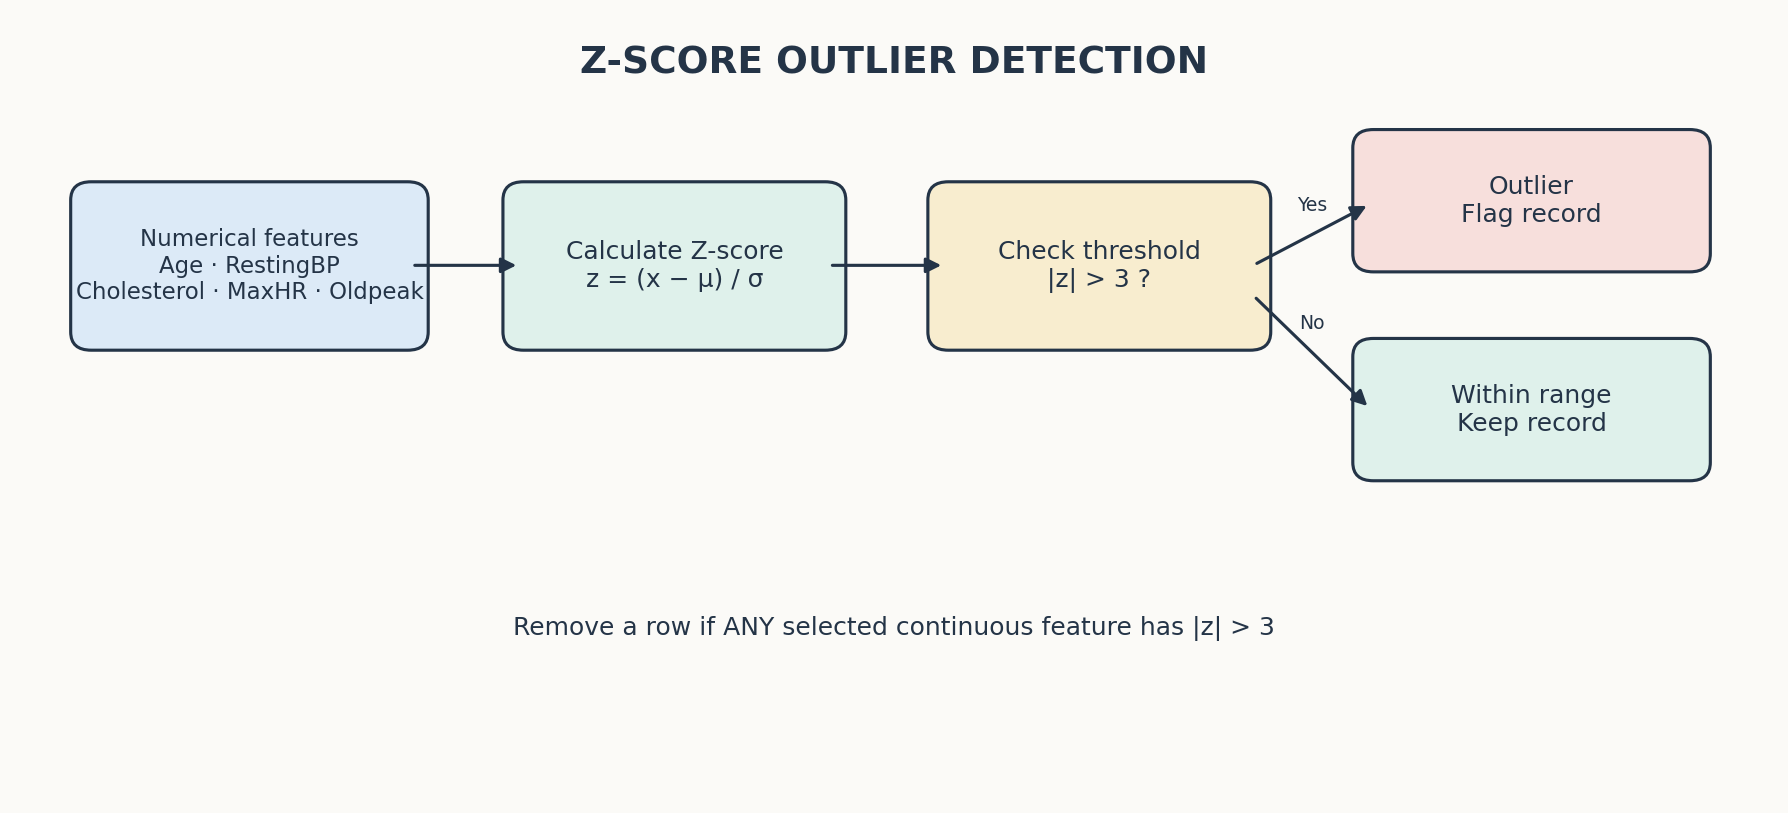

**Steps**
1. Select the numerical (continuous) features: `Age`, `RestingBP`, `Cholesterol`, `MaxHR`, `Oldpeak`.
2. Calculate the Z-score for each of these features.
3. Identify and count the records containing outliers.
4. Remove those records and report the shape of the dataset before and after removal.

> ⚠️ Do **not** compute Z-scores on the target column or on encoded/binary columns.

### 2.1 Visualise the numerical features (e.g., boxplots) before outlier removal

DESCRIPTIVE STATISTICS BEFORE OUTLIER REMOVAL
------------------------------------------------
              Age   RestingBP  Cholesterol       MaxHR     Oldpeak
count  918.000000  918.000000   918.000000  918.000000  918.000000
mean    53.510893  132.396514   198.799564  136.809368    0.887364
std      9.432617   18.514154   109.384145   25.460334    1.066570
min     28.000000    0.000000     0.000000   60.000000   -2.600000
25%     47.000000  120.000000   173.250000  120.000000    0.000000
50%     54.000000  130.000000   223.000000  138.000000    0.600000
75%     60.000000  140.000000   267.000000  156.000000    1.500000
max     77.000000  200.000000   603.000000  202.000000    6.200000


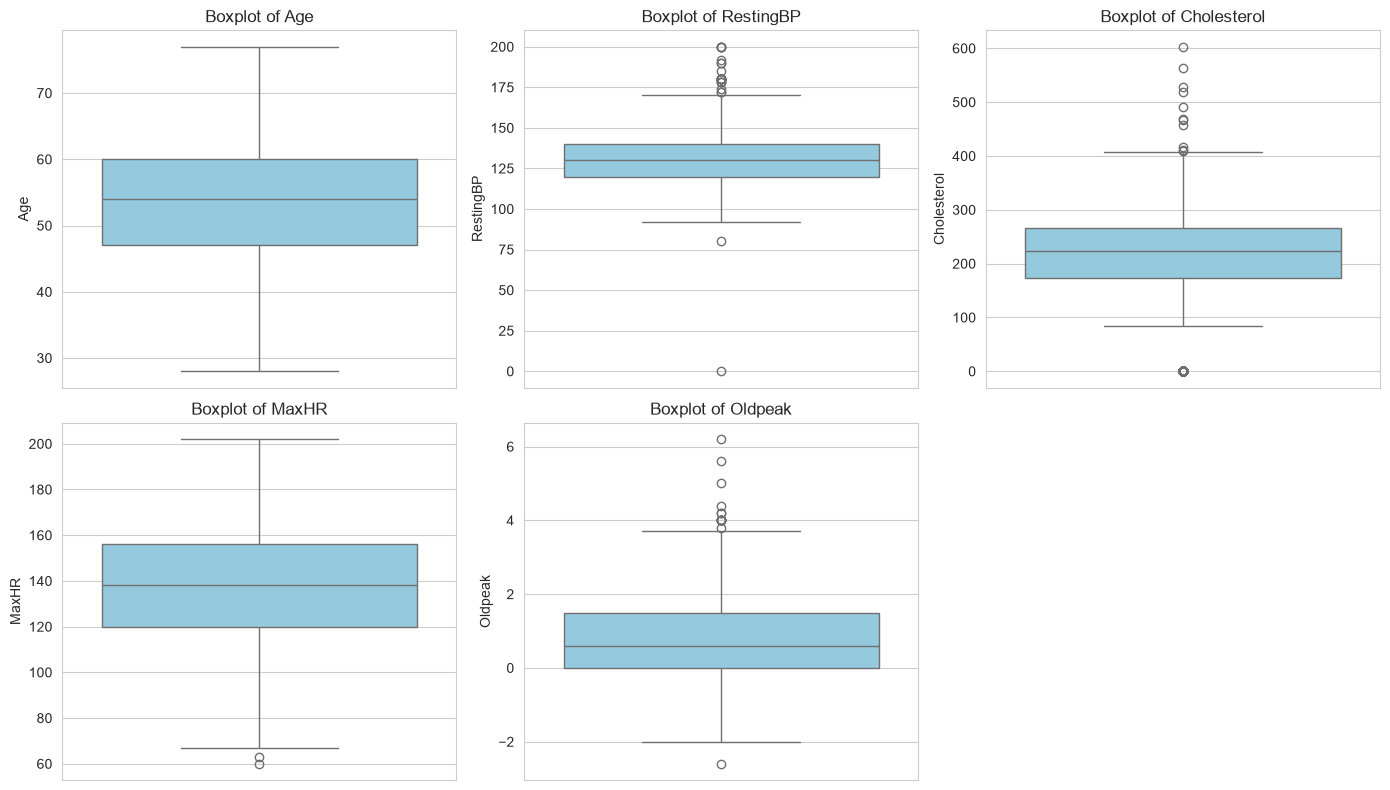


OBSERVATION
------------------------------------------------
The boxplots help identify extreme values in the numerical features.
Values located beyond the whiskers may be potential outliers.


In [9]:
# Write your code here
# ---------------------------------------------------------
# TASK 2.1: VISUALISE NUMERICAL FEATURES BEFORE OUTLIER REMOVAL
# ---------------------------------------------------------

# Select the continuous numerical features specified in the assignment
numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

# Display descriptive statistics for the selected features
print("DESCRIPTIVE STATISTICS BEFORE OUTLIER REMOVAL")
print("------------------------------------------------")
print(df[numerical_features].describe())

# Create a figure containing one boxplot for each numerical feature
plt.figure(figsize=(14, 8))

for index, feature in enumerate(numerical_features, 1):

    # Create a separate subplot for each feature
    plt.subplot(2, 3, index)

    # Draw the boxplot to identify possible outliers
    sns.boxplot(y=df[feature], color="skyblue")

    # Add title and axis label
    plt.title(f"Boxplot of {feature}")
    plt.ylabel(feature)

# Adjust spacing between subplots
plt.tight_layout()
plt.show()

# Print an observation
print("\nOBSERVATION")
print("------------------------------------------------")
print("The boxplots help identify extreme values in the numerical features.")
print("Values located beyond the whiskers may be potential outliers.")

### 2.2 Calculate Z-scores for the numerical features

In [10]:
# Write your code here
# ---------------------------------------------------------
# TASK 2.2: CALCULATE Z-SCORES
# ---------------------------------------------------------

# Select the continuous numerical features
numerical_features = [
    "Age",
    "RestingBP",
    "Cholesterol",
    "MaxHR",
    "Oldpeak"
]

# Calculate the Z-score for every numerical feature
# ddof=0 calculates the population standard deviation
z_scores = pd.DataFrame(
    zscore(df[numerical_features], axis=0, ddof=0),
    columns=numerical_features,
    index=df.index
)

# Display the first five rows of calculated Z-scores
print("FIRST FIVE RECORDS OF Z-SCORES")
print("------------------------------------------------")
print(z_scores.head())

# Display the absolute Z-scores to make extreme values easier to inspect
print("\nABSOLUTE Z-SCORES")
print("------------------------------------------------")
print(z_scores.abs().head())

# Identify values whose absolute Z-score is greater than 3
z_score_threshold = 3

# Count potential outliers in each numerical feature
outlier_counts = (z_scores.abs() > z_score_threshold).sum()

print("\nOUTLIER COUNT FOR EACH FEATURE")
print("------------------------------------------------")
print(outlier_counts)

# Print the threshold used
print("\nZ-SCORE THRESHOLD:", z_score_threshold)

FIRST FIVE RECORDS OF Z-SCORES
------------------------------------------------
        Age  RestingBP  Cholesterol     MaxHR   Oldpeak
0 -1.433140   0.410909     0.825070  1.382928 -0.832432
1 -0.478484   1.491752    -0.171961  0.754157  0.105664
2 -1.751359  -0.129513     0.770188 -1.525138 -0.832432
3 -0.584556   0.302825     0.139040 -1.132156  0.574711
4  0.051881   0.951331    -0.034755 -0.581981 -0.832432

ABSOLUTE Z-SCORES
------------------------------------------------
        Age  RestingBP  Cholesterol     MaxHR   Oldpeak
0  1.433140   0.410909     0.825070  1.382928  0.832432
1  0.478484   1.491752     0.171961  0.754157  0.105664
2  1.751359   0.129513     0.770188  1.525138  0.832432
3  0.584556   0.302825     0.139040  1.132156  0.574711
4  0.051881   0.951331     0.034755  0.581981  0.832432

OUTLIER COUNT FOR EACH FEATURE
------------------------------------------------
Age            0
RestingBP      8
Cholesterol    3
MaxHR          1
Oldpeak        7
dtype: int64



### 2.3 Identify and count the outlier records

In [11]:
# Write your code here
# ---------------------------------------------------------
# TASK 2.3: IDENTIFY AND COUNT OUTLIER RECORDS
# ---------------------------------------------------------

# A record is considered an outlier if at least one numerical
# feature has an absolute Z-score greater than 3
outlier_mask = (z_scores.abs() > 3).any(axis=1)

# Extract all records identified as outliers
outlier_records = df.loc[outlier_mask]

# Count the total number of outlier records
total_outliers = outlier_mask.sum()

# Count the number of records that are not outliers
non_outlier_count = (~outlier_mask).sum()

# Display the results
print("OUTLIER DETECTION RESULTS")
print("------------------------------------------------")
print("Total records before outlier removal:", len(df))
print("Total outlier records:", total_outliers)
print("Total non-outlier records:", non_outlier_count)

# Display the first five outlier records
print("\nFIRST FIVE OUTLIER RECORDS")
print("------------------------------------------------")
print(outlier_records.head())

# Count how many outlier values occur in each feature
feature_outlier_counts = (z_scores.abs() > 3).sum().sort_values(
    ascending=False
)

print("\nOUTLIER CONTRIBUTION BY FEATURE")
print("------------------------------------------------")
print(feature_outlier_counts)

# Identify the feature with the highest number of outlier values
most_outlier_feature = feature_outlier_counts.idxmax()

print("\nFEATURE WITH THE MOST OUTLIER VALUES:", most_outlier_feature)
print("NUMBER OF OUTLIER VALUES:", feature_outlier_counts.max())

# Note that a row can be an outlier in more than one feature
print("\nNOTE:")
print("The feature counts can overlap because one record may contain")
print("outlier values in multiple numerical features.")

OUTLIER DETECTION RESULTS
------------------------------------------------
Total records before outlier removal: 918
Total outlier records: 19
Total non-outlier records: 899

FIRST FIVE OUTLIER RECORDS
------------------------------------------------
     Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
76    32   M           ASY        118          529          0     Normal   
109   39   M           ATA        190          241          0     Normal   
149   54   M           ASY        130          603          1     Normal   
166   50   M           ASY        140          231          0         ST   
241   54   M           ASY        200          198          0     Normal   

     MaxHR ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
76     130              N      0.0     Flat             1  
109    106              N      0.0       Up             0  
149    125              Y      1.0     Flat             1  
166    140              Y      5.0     Flat         

### 2.4 Remove the outliers and display the new shape

In [12]:
# Write your code here
# ---------------------------------------------------------
# TASK 2.4: REMOVE OUTLIERS
# ---------------------------------------------------------

# Store the original dataset shape
original_shape = df.shape

# Keep only records that do not contain any outlier values
df_clean = df.loc[~outlier_mask].copy()

# Store the new dataset shape
cleaned_shape = df_clean.shape

# Calculate the number of removed records
removed_records = original_shape[0] - cleaned_shape[0]

# Display the results
print("OUTLIER REMOVAL RESULTS")
print("------------------------------------------------")
print("Original dataset shape:", original_shape)
print("Dataset shape after removing outliers:", cleaned_shape)
print("Number of records removed:", removed_records)
print("Number of records remaining:", len(df_clean))

# Calculate the percentage of records removed
percentage_removed = (removed_records / original_shape[0]) * 100

print("Percentage of records removed:", round(percentage_removed, 2), "%")

# Use the cleaned dataset for the remaining tasks
df = df_clean.copy()

print("\nThe cleaned dataset will now be used for further preprocessing.")

OUTLIER REMOVAL RESULTS
------------------------------------------------
Original dataset shape: (918, 12)
Dataset shape after removing outliers: (899, 12)
Number of records removed: 19
Number of records remaining: 899
Percentage of records removed: 2.07 %

The cleaned dataset will now be used for further preprocessing.


**Q2.** How many records were removed? Which feature contributed the most outliers?

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._

---
## Task 3: Data Encoding

Machine learning models need numerical input, so text-based features must be encoded.

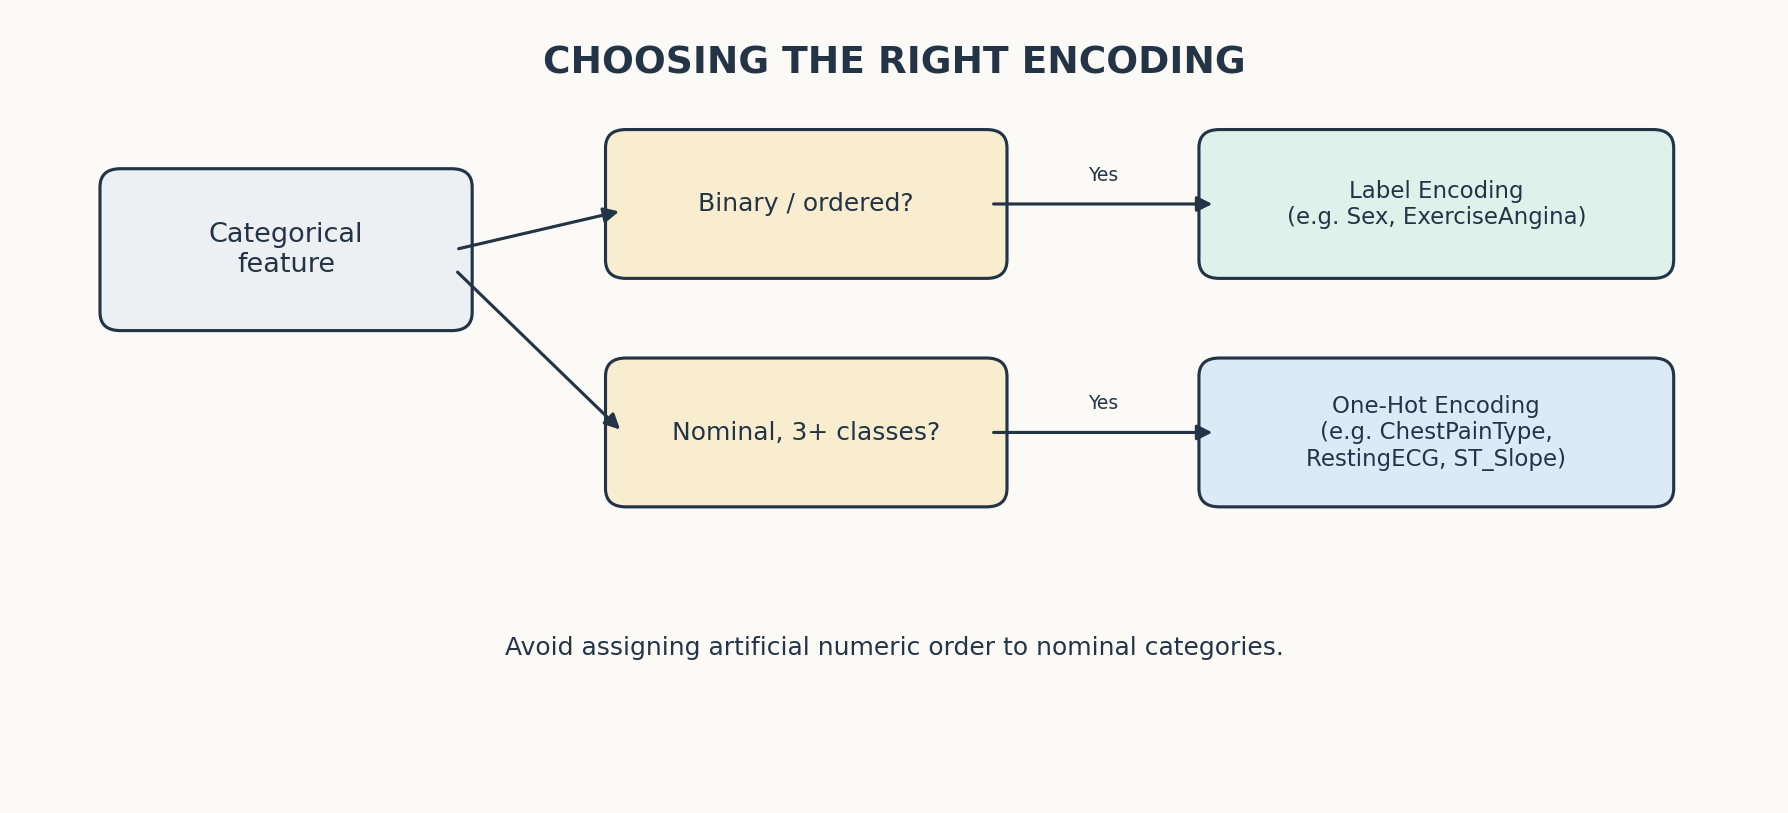

| Technique | Use it when... | Example features |
|---|---|---|
| **Label Encoding** | The feature is **binary** (2 categories) or has a natural order | `Sex`, `ExerciseAngina` |
| **One-Hot Encoding** | The feature is **nominal** with more than 2 categories (no order) | `ChestPainType`, `RestingECG`, `ST_Slope` |

> 💡 Applying Label Encoding to a nominal feature (e.g., ATA=0, NAP=1, ASY=2) makes the model think ASY > NAP > ATA, which is not meaningful.

**Steps**
1. Identify the categorical (text-based) features.
2. Apply **Label Encoding** to the binary features.
3. Apply **One-Hot Encoding** to the nominal features (consider `drop_first=True` to avoid the dummy-variable trap).
4. Display the encoded DataFrame and its new shape.

### 3.1 Identify the categorical features and their unique values

In [13]:
# Write your code here
# ---------------------------------------------------------
# TASK 3.1: IDENTIFY CATEGORICAL FEATURES
# ---------------------------------------------------------

# Identify columns containing text or categorical values
categorical_features = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Display the categorical feature names
print("CATEGORICAL FEATURES")
print("------------------------------------------------")
print(categorical_features)

# Display the unique values and their counts for every categorical feature
for feature in categorical_features:

    print(f"\nFEATURE: {feature}")
    print("----------------------------------------")

    print("Unique values:")
    print(df[feature].unique())

    print("\nValue counts:")
    print(df[feature].value_counts())

# Display the total number of categorical features
print("\nTOTAL CATEGORICAL FEATURES:", len(categorical_features))

CATEGORICAL FEATURES
------------------------------------------------
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

FEATURE: Sex
----------------------------------------
Unique values:
<StringArray>
['M', 'F']
Length: 2, dtype: str

Value counts:
Sex
M    710
F    189
Name: count, dtype: int64

FEATURE: ChestPainType
----------------------------------------
Unique values:
<StringArray>
['ATA', 'NAP', 'ASY', 'TA']
Length: 4, dtype: str

Value counts:
ChestPainType
ASY    483
NAP    200
ATA    171
TA      45
Name: count, dtype: int64

FEATURE: RestingECG
----------------------------------------
Unique values:
<StringArray>
['Normal', 'ST', 'LVH']
Length: 3, dtype: str

Value counts:
RestingECG
Normal    543
LVH       182
ST        174
Name: count, dtype: int64

FEATURE: ExerciseAngina
----------------------------------------
Unique values:
<StringArray>
['N', 'Y']
Length: 2, dtype: str

Value counts:
ExerciseAngina
N    536
Y    363
Name: count, dtype: int64

FEAT

### 3.2 Apply Label Encoding

In [14]:
# Write your code here
# ---------------------------------------------------------
# TASK 3.2: APPLY LABEL ENCODING
# ---------------------------------------------------------

# Create a separate copy of the cleaned dataset
df_encoded = df.copy()

# Define the binary categorical features
binary_features = [
    "Sex",
    "ExerciseAngina"
]

# Apply explicit binary mappings to maintain consistent encoding
# Sex: M = 1, F = 0
# ExerciseAngina: Y = 1, N = 0
binary_mappings = {
    "Sex": {
        "F": 0,
        "M": 1
    },
    "ExerciseAngina": {
        "N": 0,
        "Y": 1
    }
}

# Apply the mappings to the respective columns
for feature in binary_features:

    df_encoded[feature] = df_encoded[feature].map(
        binary_mappings[feature]
    )

# Display the encoded binary columns
print("LABEL ENCODED FEATURES")
print("------------------------------------------------")
print(df_encoded[binary_features].head())

# Verify that the binary features contain only numerical values
for feature in binary_features:

    print(f"\n{feature} unique encoded values:")
    print(df_encoded[feature].unique())

# Check whether any values became missing during mapping
print("\nMISSING VALUES AFTER LABEL ENCODING")
print("------------------------------------------------")
print(df_encoded[binary_features].isnull().sum())

LABEL ENCODED FEATURES
------------------------------------------------
   Sex  ExerciseAngina
0    1               0
1    0               0
2    1               0
3    0               1
4    1               0

Sex unique encoded values:
[1 0]

ExerciseAngina unique encoded values:
[0 1]

MISSING VALUES AFTER LABEL ENCODING
------------------------------------------------
Sex               0
ExerciseAngina    0
dtype: int64


### 3.3 Apply One-Hot Encoding

In [15]:
# Write your code here
# ---------------------------------------------------------
# TASK 3.3: APPLY ONE-HOT ENCODING
# ---------------------------------------------------------

# Define nominal categorical features
# These features do not have a meaningful numerical order
nominal_features = [
    "ChestPainType",
    "RestingECG",
    "ST_Slope"
]

# Apply one-hot encoding to the nominal categorical features
# drop_first=True removes one reference category per feature
df_encoded = pd.get_dummies(
    df_encoded,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

# Display the first five rows after one-hot encoding
print("DATASET AFTER ONE-HOT ENCODING")
print("------------------------------------------------")
print(df_encoded.head())

# Display the newly generated columns
print("\nGENERATED ONE-HOT ENCODED COLUMNS")
print("------------------------------------------------")

for feature in nominal_features:

    generated_columns = [
        column for column in df_encoded.columns
        if column.startswith(feature + "_")
    ]

    print(f"\n{feature}:")
    print(generated_columns)

# Verify that no text-based columns remain
remaining_text_columns = df_encoded.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nREMAINING TEXT-BASED COLUMNS:")
print(remaining_text_columns)

DATASET AFTER ONE-HOT ENCODING
------------------------------------------------
   Age  Sex  RestingBP  Cholesterol  FastingBS  MaxHR  ExerciseAngina  \
0   40    1        140          289          0    172               0   
1   49    0        160          180          0    156               0   
2   37    1        130          283          0     98               0   
3   48    0        138          214          0    108               1   
4   54    1        150          195          0    122               0   

   Oldpeak  HeartDisease  ChestPainType_ATA  ChestPainType_NAP  \
0      0.0             0                  1                  0   
1      1.0             1                  0                  1   
2      0.0             0                  1                  0   
3      1.5             1                  0                  0   
4      0.0             0                  0                  1   

   ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ST_Slope_Flat  \
0           

### 3.4 Display the final encoded dataset

In [16]:
# Write your code here
# ---------------------------------------------------------
# TASK 3.4: DISPLAY FINAL ENCODED DATASET
# ---------------------------------------------------------

# Display the first five records of the encoded dataset
print("FINAL ENCODED DATASET")
print("------------------------------------------------")
print(df_encoded.head())

# Display the dimensions of the encoded dataset
print("\nDATASET SHAPE AFTER ENCODING")
print("------------------------------------------------")
print("Number of rows:", df_encoded.shape[0])
print("Number of columns:", df_encoded.shape[1])

# Display all feature names
print("\nFINAL COLUMN NAMES")
print("------------------------------------------------")
print(df_encoded.columns.tolist())

# Display the data types of all columns
print("\nDATA TYPES AFTER ENCODING")
print("------------------------------------------------")
print(df_encoded.dtypes)

# Check whether any categorical text columns remain
print("\nREMAINING CATEGORICAL COLUMNS")
print("------------------------------------------------")
print(
    df_encoded.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

# Verify missing values after encoding
print("\nMISSING VALUES")
print("------------------------------------------------")
print(df_encoded.isnull().sum().sum())

FINAL ENCODED DATASET
------------------------------------------------
   Age  Sex  RestingBP  Cholesterol  FastingBS  MaxHR  ExerciseAngina  \
0   40    1        140          289          0    172               0   
1   49    0        160          180          0    156               0   
2   37    1        130          283          0     98               0   
3   48    0        138          214          0    108               1   
4   54    1        150          195          0    122               0   

   Oldpeak  HeartDisease  ChestPainType_ATA  ChestPainType_NAP  \
0      0.0             0                  1                  0   
1      1.0             1                  0                  1   
2      0.0             0                  1                  0   
3      1.5             1                  0                  0   
4      0.0             0                  0                  1   

   ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ST_Slope_Flat  \
0                 0  

**Q3.** Justify the encoding technique you chose for each categorical feature. How many features does the dataset have after encoding?

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._
> Different encoding techniques were used depending on the nature of each categorical feature.

1. Label Encoding – Sex and ExerciseAngina

These features contain only two categories, so binary numerical encoding was used.
- Sex: Male = 1, Female = 0
- ExerciseAngina: Yes = 1, No = 0
This technique is suitable because both features have only two possible values, allowing them to be represented numerically without creating additional columns.

2. One-Hot Encoding – ChestPainType, RestingECG and ST_Slope

These features contain multiple categories without a meaningful numerical order. One-hot encoding was therefore used to represent each category as a separate binary column.

drop_first=True was used to remove one reference category from each feature, reducing redundancy and avoiding unnecessary columns.

Number of features after encoding:

The original dataset contains 11 independent features, excluding the target variable HeartDisease. After encoding:
- Original numerical features: 6
- Binary encoded features: 2
- One-hot encoded features: 7
15 independent features
Therefore, the dataset contains 15 independent features after encoding, excluding the target variable HeartDisease.

---
## Task 4: Train–Test Split and Feature Scaling

Distance-based models (KNN) and gradient-based models (Logistic Regression) are sensitive to feature scale, so features must be normalised.

To avoid **data leakage**, the scaler must learn its parameters ($\mu$, $\sigma$ or min/max) **only from the training set**, and then apply those same parameters to the test set.

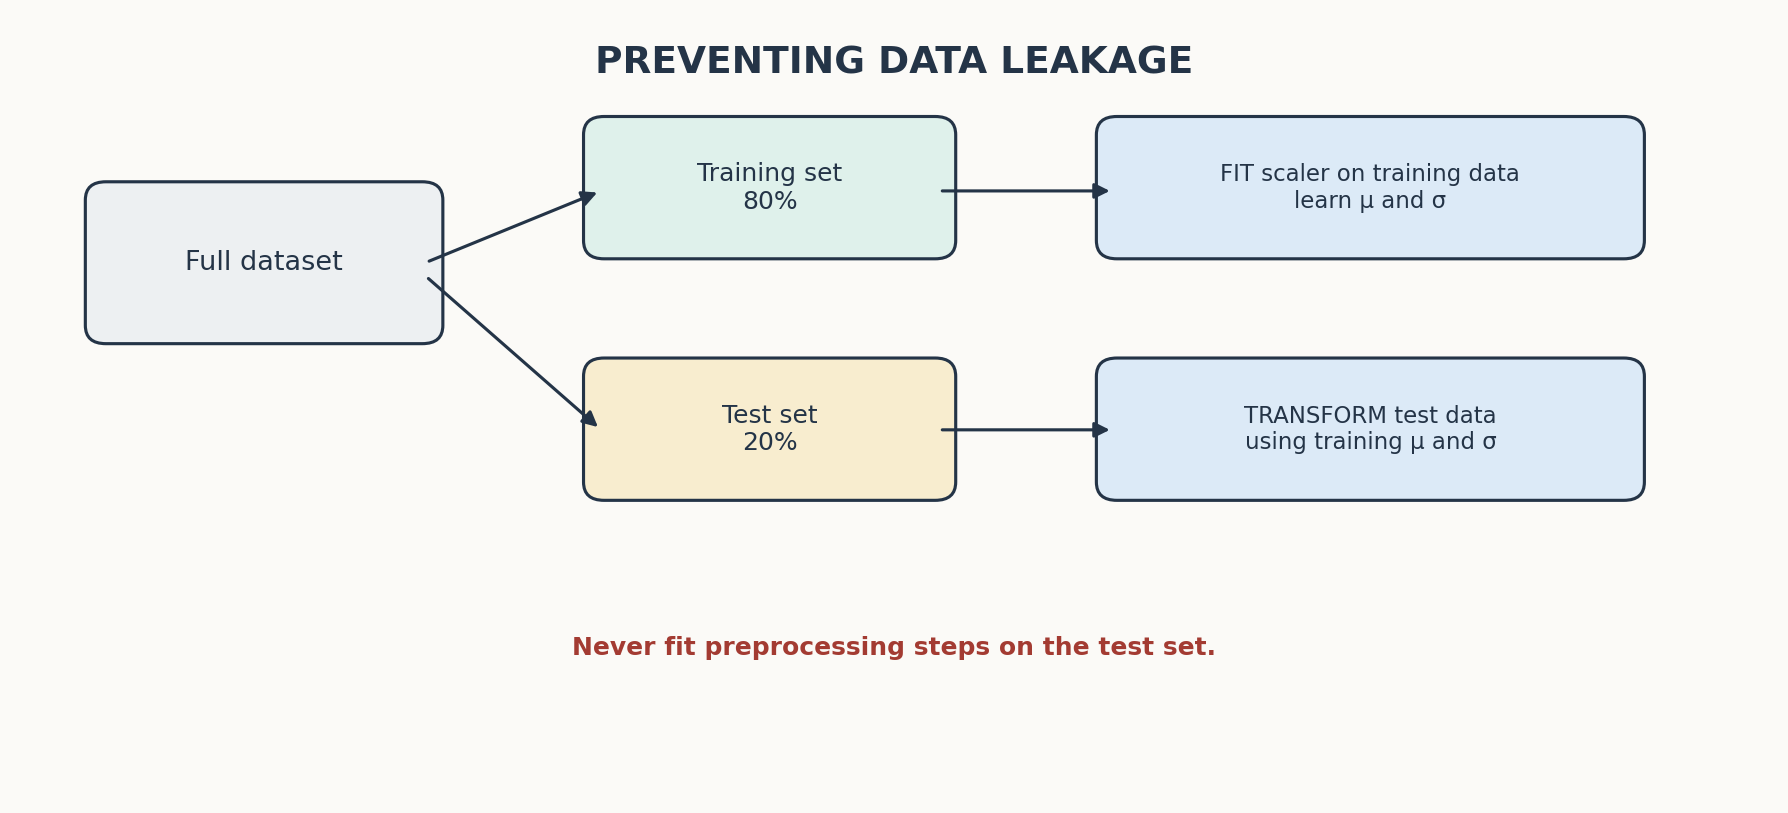

**Steps**
1. Separate the features `X` and the target `y` (`HeartDisease`).
2. Split the data into training and testing sets (e.g., 80/20, `stratify=y`, `random_state=42`).
3. Fit `StandardScaler` (or `MinMaxScaler`) on `X_train` only, then transform both `X_train` and `X_test`.

> 💡 This train/test split will be reused in Tasks 5–8 so that all comparisons are fair.

### 4.1 Separate features and target

In [17]:
# Write your code here
# ---------------------------------------------------------
# TASK 4.1: SEPARATE FEATURES AND TARGET
# ---------------------------------------------------------

# Separate independent features from the target variable
# HeartDisease is the variable that the models must predict
X = df_encoded.drop(columns=["HeartDisease"])

# Store the target variable separately
y = df_encoded["HeartDisease"]

# Display the feature dataset
print("INDEPENDENT FEATURES")
print("------------------------------------------------")
print(X.head())

# Display the target variable
print("\nTARGET VARIABLE")
print("------------------------------------------------")
print(y.head())

# Display the shapes of X and y
print("\nDATASET DIMENSIONS")
print("------------------------------------------------")
print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

# Display the target class distribution
print("\nTARGET CLASS DISTRIBUTION")
print("------------------------------------------------")
print(y.value_counts())

INDEPENDENT FEATURES
------------------------------------------------
   Age  Sex  RestingBP  Cholesterol  FastingBS  MaxHR  ExerciseAngina  \
0   40    1        140          289          0    172               0   
1   49    0        160          180          0    156               0   
2   37    1        130          283          0     98               0   
3   48    0        138          214          0    108               1   
4   54    1        150          195          0    122               0   

   Oldpeak  ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  \
0      0.0                  1                  0                 0   
1      1.0                  0                  1                 0   
2      0.0                  1                  0                 0   
3      1.5                  0                  0                 0   
4      0.0                  0                  1                 0   

   RestingECG_Normal  RestingECG_ST  ST_Slope_Flat  ST_Slope_Up  
0   

### 4.2 Split into training and testing sets

In [18]:
# Write your code here
# ---------------------------------------------------------
# TASK 4.2: TRAIN-TEST SPLIT
# ---------------------------------------------------------

# Split the dataset into training and testing sets
# 80% of the data is used for training and 20% for testing
# stratify=y maintains the original target class distribution
# random_state=42 ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes of the resulting datasets
print("TRAIN-TEST SPLIT RESULTS")
print("------------------------------------------------")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Verify class distribution in the training and testing sets
print("\nTRAINING SET CLASS DISTRIBUTION")
print("------------------------------------------------")
print(y_train.value_counts(normalize=True) * 100)

print("\nTESTING SET CLASS DISTRIBUTION")
print("------------------------------------------------")
print(y_test.value_counts(normalize=True) * 100)

TRAIN-TEST SPLIT RESULTS
------------------------------------------------
X_train shape: (719, 15)
X_test shape: (180, 15)
y_train shape: (719,)
y_test shape: (180,)

TRAINING SET CLASS DISTRIBUTION
------------------------------------------------
HeartDisease
1    54.659249
0    45.340751
Name: proportion, dtype: float64

TESTING SET CLASS DISTRIBUTION
------------------------------------------------
HeartDisease
1    55.0
0    45.0
Name: proportion, dtype: float64


### 4.3 Apply feature scaling (fit on training data only)

In [19]:
# Write your code here
# ---------------------------------------------------------
# TASK 4.3: APPLY STANDARD SCALING
# ---------------------------------------------------------

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler only on the training data
# This calculates the mean and standard deviation from X_train
scaler.fit(X_train)

# Transform the training data using the fitted scaler
X_train_scaled = pd.DataFrame(
    scaler.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Transform the testing data using the same fitted scaler
# Do not fit the scaler again on the testing data
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Display the first five scaled training records
print("SCALED TRAINING DATA")
print("------------------------------------------------")
print(X_train_scaled.head())

# Display the first five scaled testing records
print("\nSCALED TESTING DATA")
print("------------------------------------------------")
print(X_test_scaled.head())

# Display the shapes after scaling
print("\nSHAPES AFTER SCALING")
print("------------------------------------------------")
print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

# Verify that the training features are approximately standardised
print("\nTRAINING DATA MEAN AFTER SCALING")
print("------------------------------------------------")
print(X_train_scaled.mean().round(3))

print("\nTRAINING DATA STANDARD DEVIATION AFTER SCALING")
print("------------------------------------------------")
print(X_train_scaled.std(ddof=0).round(3))

SCALED TRAINING DATA
------------------------------------------------
          Age       Sex  RestingBP  Cholesterol  FastingBS     MaxHR  \
192 -0.588355  0.530698  -0.124037     0.411677  -0.541448  0.924319   
139 -1.107789  0.530698   1.060329     0.430614  -0.541448 -0.267050   
195  0.866060 -1.884312   1.652513    -0.080702  -0.541448 -0.823022   
135 -0.484468  0.530698  -1.012312     0.601053  -0.541448  1.520004   
211 -0.380581 -1.884312   0.468146     0.818837  -0.541448  0.130073   

     ExerciseAngina   Oldpeak  ChestPainType_ATA  ChestPainType_NAP  \
192       -0.824564 -0.853342           2.024671          -0.524235   
139        1.212761  1.136452          -0.493908          -0.524235   
195       -0.824564 -0.853342          -0.493908          -0.524235   
135       -0.824564 -0.853342          -0.493908           1.907540   
211        1.212761 -0.853342          -0.493908           1.907540   

     ChestPainType_TA  RestingECG_Normal  RestingECG_ST  ST_Slope_Flat

**Q4.** Which scaler did you choose and why? Explain what would go wrong if you fitted the scaler on the entire dataset before splitting.
I chose StandardScaler from Scikit-learn because it standardizes numerical features so that they have a mean of approximately 0 and a standard deviation of 1.

> ✍️ **Your answer:**
>
> _Double-click this cell and write your answer here._
> The formula is:
\\[ \boxed{z=\frac{x-\mu}{\sigma}} \\]

Where:

- \\(z\\) = Standardized value (Z-score)
- \\(x\\) = Original feature value
- \\(\mu\\) = Mean of the feature
- \\(\sigma\\) = Standard deviation of the feature
Why StandardScaler?

The Heart Disease dataset contains numerical features with different scales, such as Age, Cholesterol, RestingBP, and MaxHR. StandardScaler brings these features to a comparable scale. This is particularly important for distance-based algorithms like KNN and helps optimization-based models like Logistic Regression.

What if we fit the scaler before splitting the dataset?

Fitting the scaler on the entire dataset would cause data leakage.

This happens because the scaler would calculate the mean and standard deviation using both training and testing data. As a result, information from the test set would indirectly influence the training process.

This can lead to:
- An unrealistic evaluation of model performance.
- Biased test results.
- Poorer generalization to completely unseen data.
Correct approach:
1. Split the dataset into training and testing sets.
2. Fit the scaler only on the training data.
3. Transform both training and testing data using the same fitted scaler.

---
## Task 5: Classification Model Development (Before Tuning)

Build and evaluate the following four classifiers using their **default** hyperparameters:

1. K-Nearest Neighbors (KNN)
2. Logistic Regression
3. Decision Tree
4. Random Forest

For each model, report **Accuracy, Precision, Recall and F1-score** on the test set, and display the **confusion matrix**.

| Metric | Formula | Meaning in this problem |
|---|---|---|
| Accuracy | $\frac{TP + TN}{TP + TN + FP + FN}$ | Overall fraction of correct predictions |
| Precision | $\frac{TP}{TP + FP}$ | Of patients predicted to have heart disease, how many actually do |
| Recall | $\frac{TP}{TP + FN}$ | Of patients who actually have heart disease, how many were detected |
| F1-score | $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$ | Balance between precision and recall |

> 💡 *Tip:* Write a reusable function, e.g. `evaluate_model(model, X_train, X_test, y_train, y_test)`, that trains a model, measures training time and returns all metrics.

### 5.1 Write a helper function for training and evaluation

In [20]:
# Write your code here
# ---------------------------------------------------------
# TASK 5.1: HELPER FUNCTION FOR MODEL EVALUATION
# ---------------------------------------------------------

# Define a reusable function to train and evaluate classification models
def evaluate_model(model, X_train, X_test, y_train, y_test):

    # Record the starting time
    start_time = time.time()

    # Train the model using the training dataset
    model.fit(X_train, y_train)

    # Calculate the training time
    training_time = time.time() - start_time

    # Predict the target values for the test dataset
    y_pred = model.predict(X_test)

    # Calculate the evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    # Calculate the confusion matrix
    cm = confusion_matrix(y_test, y_pred)

    # Display model evaluation results
    print("\nMODEL:", type(model).__name__)
    print("----------------------------------------")
    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-score :", round(f1, 4))
    print("Training Time:", round(training_time, 4), "seconds")

    # Display the confusion matrix
    print("\nConfusion Matrix:")
    print(cm)

    # Return the trained model and its evaluation results
    return {
        "Model": type(model).__name__,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Training Time": training_time,
        "Confusion Matrix": cm,
        "Trained Model": model
    }


# Create a dictionary to store results of all default models
default_results = {}

print("MODEL EVALUATION FUNCTION CREATED SUCCESSFULLY.")

MODEL EVALUATION FUNCTION CREATED SUCCESSFULLY.


### 5.2 K-Nearest Neighbors


MODEL: KNeighborsClassifier
----------------------------------------
Accuracy : 0.8889
Precision: 0.8835
Recall   : 0.9192
F1-score : 0.901
Training Time: 0.0171 seconds

Confusion Matrix:
[[69 12]
 [ 8 91]]


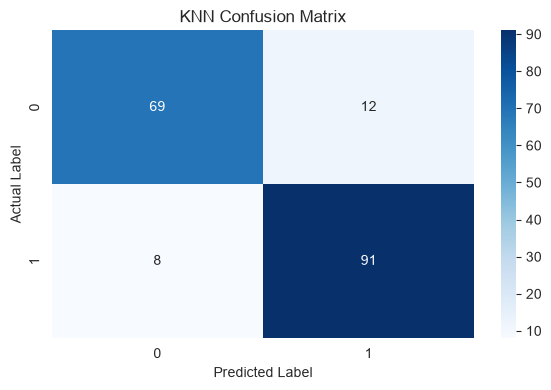

In [21]:
# Write your code here
# ---------------------------------------------------------
# TASK 5.2: K-NEAREST NEIGHBORS CLASSIFIER
# ---------------------------------------------------------

# Create a KNN classifier using default hyperparameters
knn_model = KNeighborsClassifier()

# Train and evaluate the KNN classifier
knn_result = evaluate_model(
    knn_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the KNN results
default_results["KNN"] = knn_result

# Visualise the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    knn_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### 5.3 Logistic Regression


MODEL: LogisticRegression
----------------------------------------
Accuracy : 0.8722
Precision: 0.8725
Recall   : 0.899
F1-score : 0.8856
Training Time: 0.0158 seconds

Confusion Matrix:
[[68 13]
 [10 89]]


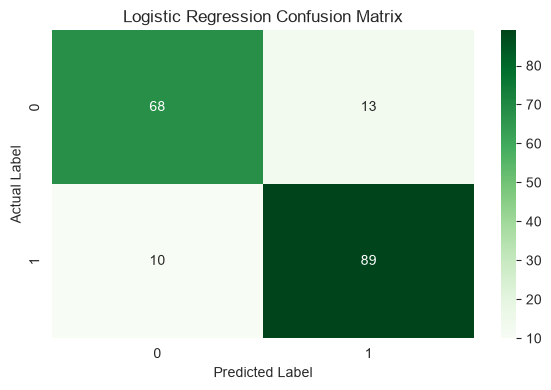

In [22]:
# Write your code here
# ---------------------------------------------------------
# TASK 5.3: LOGISTIC REGRESSION CLASSIFIER
# ---------------------------------------------------------

# Create a Logistic Regression classifier
# max_iter is increased to allow sufficient iterations for convergence
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train and evaluate the Logistic Regression classifier
logistic_result = evaluate_model(
    logistic_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the Logistic Regression results
default_results["Logistic Regression"] = logistic_result

# Visualise the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    logistic_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### 5.4 Decision Tree


MODEL: DecisionTreeClassifier
----------------------------------------
Accuracy : 0.8167
Precision: 0.83
Recall   : 0.8384
F1-score : 0.8342
Training Time: 0.0201 seconds

Confusion Matrix:
[[64 17]
 [16 83]]


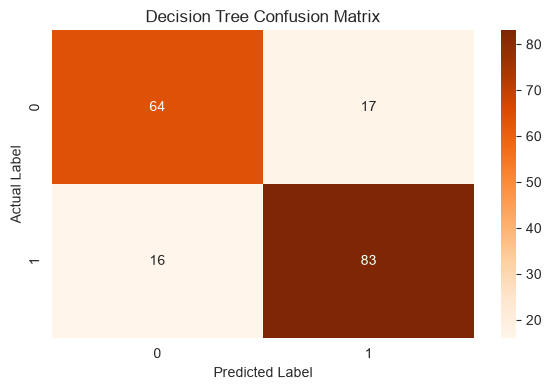

In [23]:
# Write your code here
# ---------------------------------------------------------
# TASK 5.4: DECISION TREE CLASSIFIER
# ---------------------------------------------------------

# Create a Decision Tree classifier
tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train and evaluate the Decision Tree classifier
tree_result = evaluate_model(
    tree_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the Decision Tree results
default_results["Decision Tree"] = tree_result

# Visualise the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    tree_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Oranges"
)

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### 5.5 Random Forest


MODEL: RandomForestClassifier
----------------------------------------
Accuracy : 0.8722
Precision: 0.8654
Recall   : 0.9091
F1-score : 0.8867
Training Time: 0.1869 seconds

Confusion Matrix:
[[67 14]
 [ 9 90]]


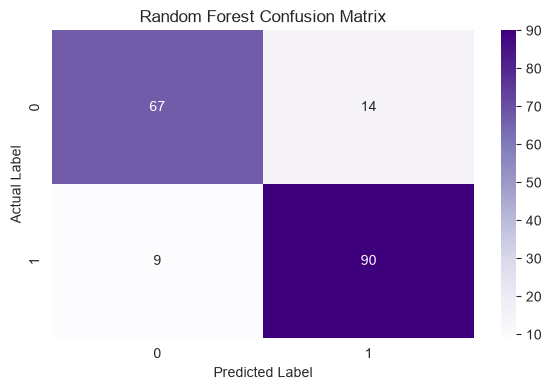

In [24]:
# Write your code here
# ---------------------------------------------------------
# TASK 5.5: RANDOM FOREST CLASSIFIER
# ---------------------------------------------------------

# Create a Random Forest classifier
forest_model = RandomForestClassifier(
    random_state=42
)

# Train and evaluate the Random Forest classifier
forest_result = evaluate_model(
    forest_model,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the Random Forest results
default_results["Random Forest"] = forest_result

# Visualise the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    forest_result["Confusion Matrix"],
    annot=True,
    fmt="d",
    cmap="Purples"
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### 5.6 Comparison table and bar chart of all four models

DEFAULT MODEL COMPARISON
------------------------------------------------
              Model  Accuracy  Precision  Recall  F1-score  Training Time
                KNN    0.8889     0.8835  0.9192    0.9010         0.0171
Logistic Regression    0.8722     0.8725  0.8990    0.8856         0.0158
      Decision Tree    0.8167     0.8300  0.8384    0.8342         0.0201
      Random Forest    0.8722     0.8654  0.9091    0.8867         0.1869

BEST MODEL BASED ON ACCURACY
------------------------------------------------
Model                 KNN
Accuracy         0.888889
Precision        0.883495
Recall           0.919192
F1-score          0.90099
Training Time    0.017105
Name: 0, dtype: object


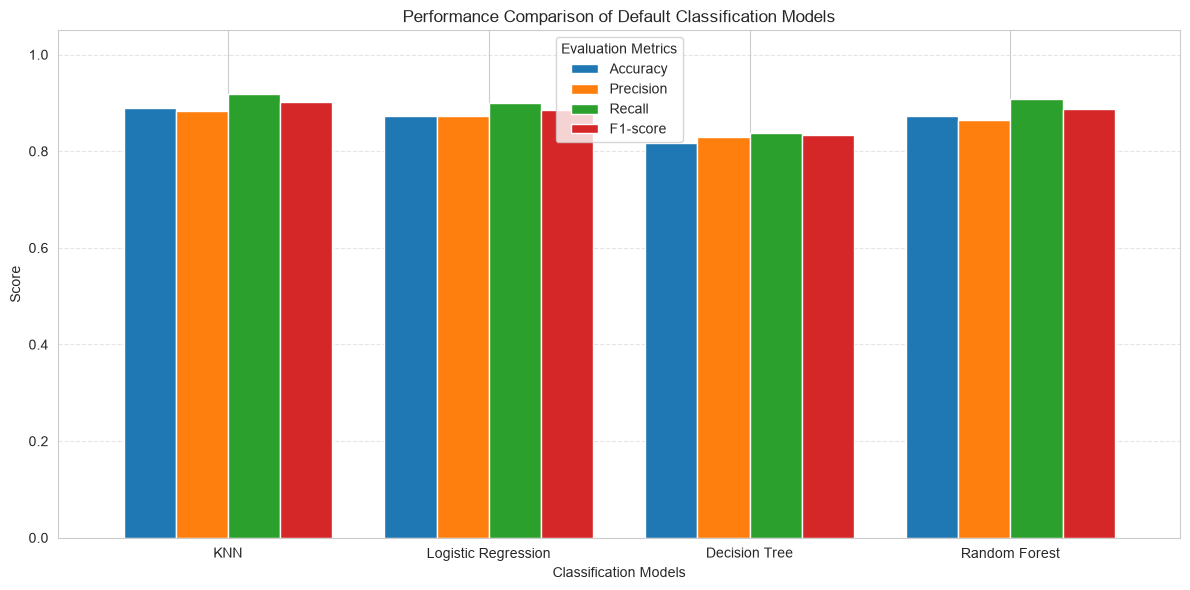

In [25]:
# Write your code here
# ---------------------------------------------------------
# TASK 5.6: COMPARE ALL DEFAULT CLASSIFICATION MODELS
# ---------------------------------------------------------

# Convert the stored evaluation results into a DataFrame
default_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1-score": result["F1-score"],
        "Training Time": result["Training Time"]
    }
    for name, result in default_results.items()
])

# Display the comparison table
print("DEFAULT MODEL COMPARISON")
print("------------------------------------------------")
print(default_comparison.round(4).to_string(index=False))

# Identify the model with the highest test accuracy
best_default_model = default_comparison.loc[
    default_comparison["Accuracy"].idxmax()
]

print("\nBEST MODEL BASED ON ACCURACY")
print("------------------------------------------------")
print(best_default_model)

# Convert the metrics into a format suitable for plotting
plot_data = default_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

# Create a grouped bar chart
plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison of Default Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Q5.** Which model achieved the highest test accuracy? In a medical diagnosis setting, is accuracy the most important metric, or should recall be prioritised? Explain.

> ✍️ **Your answer:**
>
>
The K-Nearest Neighbors (KNN) model achieved the highest test accuracy of 88.89% among the four models.

Model comparison:

| Model               | Accuracy | Recall |
| ------------------- | -------- | ------ |
| KNN                 | 88.89%   | 91.92% |
| Logistic Regression | 87.22%   | 89.90% |
| Decision Tree       | 81.67%   | 83.84% |
| Random Forest       | 87.22%   | 90.91% |

Should accuracy or recall be prioritised?

In medical diagnosis, recall should generally be prioritised because it measures how many actual positive cases are correctly identified.

\\[ \text{Recall}=\frac{TP}{TP+FN} \\]

Where:

- \\(TP\\) = True Positives
- \\(FN\\) = False Negatives

A low recall means more patients who actually have heart disease may be incorrectly classified as healthy. This can delay diagnosis and treatment.

In our results, KNN achieved the highest recall of 91.92%, meaning it correctly identified approximately 91.92% of the actual heart disease cases in the test set.

Conclusion: KNN performed best, achieving 88.89% accuracy, 91.92% recall and an F1-score of 90.10%. For heart disease prediction, recall is particularly important because missing an actual heart disease case can have serious consequences.

---
## Task 6: Hyperparameter Tuning Using Cross-Validation

Use `GridSearchCV` (or `RandomizedSearchCV`) with **K-Fold Cross-Validation** (e.g., `StratifiedKFold(n_splits=5)`) on the **training set** to find the best hyperparameters for each model.

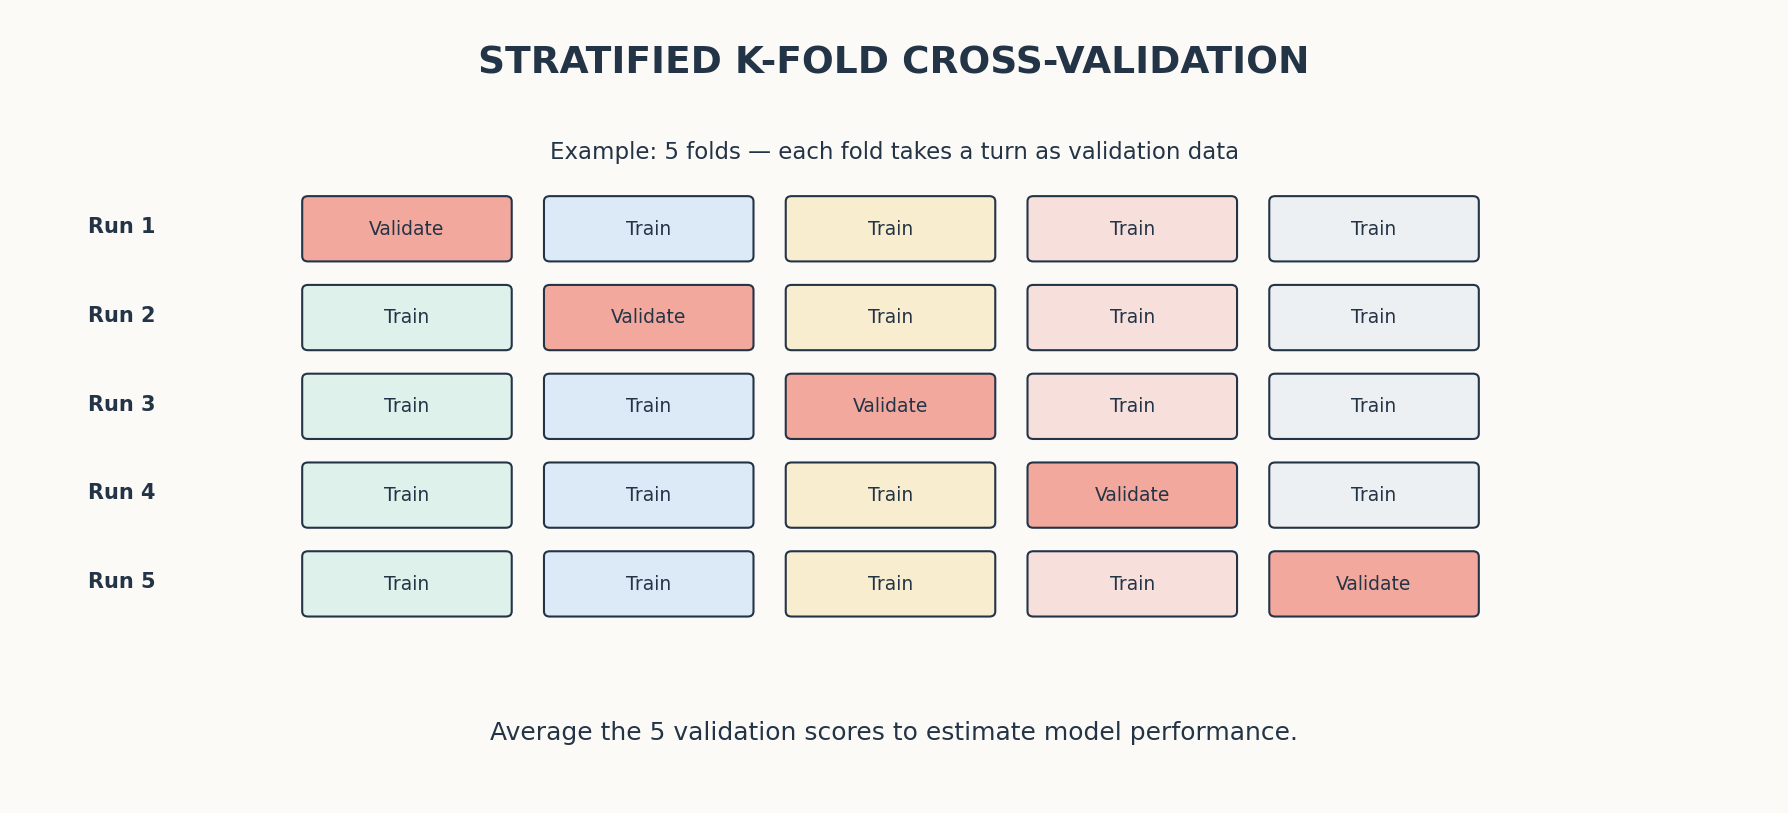

**Suggested hyperparameter grids** (you may extend them):

| Model | Hyperparameters to tune |
|---|---|
| KNN | `n_neighbors`, `weights`, `metric` |
| Logistic Regression | `C`, `penalty`, `solver` |
| Decision Tree | `max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion` |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_split`, `max_features` |

**Steps**
1. Define a parameter grid for each model.
2. Run the grid search with K-Fold cross-validation.
3. Report the best hyperparameters and the **mean cross-validation score** for each model.
4. Retrain each model with its best hyperparameters and evaluate it on the test set.
5. Compare the tuned models and identify the best-performing one.

### 6.1 Define the cross-validation strategy and parameter grids

In [26]:
# Write your code here
# ---------------------------------------------------------
# TASK 6.1: CROSS-VALIDATION STRATEGY AND PARAMETER GRIDS
# ---------------------------------------------------------

# Create Stratified K-Fold cross-validation
# Each fold maintains approximately the same class distribution
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define hyperparameter combinations for KNN
knn_param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

# Define hyperparameter combinations for Logistic Regression
logistic_param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "penalty": ["l2"],
    "solver": ["lbfgs"]
}

# Define hyperparameter combinations for Decision Tree
tree_param_grid = {
    "max_depth": [None, 3, 5, 7, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

# Define hyperparameter combinations for Random Forest
forest_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

# Display the cross-validation configuration
print("CROSS-VALIDATION STRATEGY")
print("------------------------------------------------")
print("Method: Stratified K-Fold")
print("Number of folds:", cv_strategy.n_splits)
print("Shuffle:", cv_strategy.shuffle)
print("Random state: 42")

# Display all parameter grids
print("\nKNN PARAMETER GRID:")
print(knn_param_grid)

print("\nLOGISTIC REGRESSION PARAMETER GRID:")
print(logistic_param_grid)

print("\nDECISION TREE PARAMETER GRID:")
print(tree_param_grid)

print("\nRANDOM FOREST PARAMETER GRID:")
print(forest_param_grid)

CROSS-VALIDATION STRATEGY
------------------------------------------------
Method: Stratified K-Fold
Number of folds: 5
Shuffle: True
Random state: 42

KNN PARAMETER GRID:
{'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}

LOGISTIC REGRESSION PARAMETER GRID:
{'C': [0.01, 0.1, 1, 10, 100], 'penalty': ['l2'], 'solver': ['lbfgs']}

DECISION TREE PARAMETER GRID:
{'max_depth': [None, 3, 5, 7, 10], 'min_samples_split': [2, 5, 10], 'min_samples_leaf': [1, 2, 4], 'criterion': ['gini', 'entropy']}

RANDOM FOREST PARAMETER GRID:
{'n_estimators': [100, 200], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5], 'max_features': ['sqrt', 'log2']}


### 6.2 Tune KNN

In [27]:
# Write your code here
# ---------------------------------------------------------
# TASK 6.2: HYPERPARAMETER TUNING FOR KNN
# ---------------------------------------------------------

# Create GridSearchCV for KNN
knn_grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Measure the total grid-search training time
start_time = time.time()

# Perform hyperparameter tuning using the training data only
knn_grid_search.fit(X_train_scaled, y_train)

knn_tuning_time = time.time() - start_time

# Retrieve the best KNN model
best_knn = knn_grid_search.best_estimator_

# Display the best parameters and cross-validation score
print("\nKNN TUNING RESULTS")
print("------------------------------------------------")
print("Best Parameters:", knn_grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(knn_grid_search.best_score_, 4))
print("Grid Search Time:", round(knn_tuning_time, 4), "seconds")

# Evaluate the tuned KNN model on the test dataset
tuned_knn_result = evaluate_model(
    best_knn,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the tuned results
tuned_knn_result["Best CV Score"] = knn_grid_search.best_score_
tuned_knn_result["Grid Search Time"] = knn_tuning_time

Fitting 5 folds for each of 20 candidates, totalling 100 fits

KNN TUNING RESULTS
------------------------------------------------
Best Parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}
Best Cross-Validation Accuracy: 0.8803
Grid Search Time: 6.4361 seconds

MODEL: KNeighborsClassifier
----------------------------------------
Accuracy : 0.8944
Precision: 0.8922
Recall   : 0.9192
F1-score : 0.9055
Training Time: 0.0032 seconds

Confusion Matrix:
[[70 11]
 [ 8 91]]


### 6.3 Tune Logistic Regression

In [28]:
# Write your code here
# ---------------------------------------------------------
# TASK 6.3: HYPERPARAMETER TUNING FOR LOGISTIC REGRESSION
# ---------------------------------------------------------

# Create GridSearchCV for Logistic Regression
logistic_grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    param_grid=logistic_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Measure grid-search execution time
start_time = time.time()

# Perform hyperparameter tuning on the training data
logistic_grid_search.fit(X_train_scaled, y_train)

logistic_tuning_time = time.time() - start_time

# Retrieve the best Logistic Regression model
best_logistic = logistic_grid_search.best_estimator_

# Display the tuning results
print("\nLOGISTIC REGRESSION TUNING RESULTS")
print("------------------------------------------------")
print("Best Parameters:", logistic_grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(logistic_grid_search.best_score_, 4))
print("Grid Search Time:", round(logistic_tuning_time, 4), "seconds")

# Evaluate the tuned Logistic Regression model
tuned_logistic_result = evaluate_model(
    best_logistic,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the tuning information
tuned_logistic_result["Best CV Score"] = logistic_grid_search.best_score_
tuned_logistic_result["Grid Search Time"] = logistic_tuning_time

Fitting 5 folds for each of 5 candidates, totalling 25 fits

LOGISTIC REGRESSION TUNING RESULTS
------------------------------------------------
Best Parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best Cross-Validation Accuracy: 0.8678
Grid Search Time: 0.1366 seconds

MODEL: LogisticRegression
----------------------------------------
Accuracy : 0.8778
Precision: 0.8738
Recall   : 0.9091
F1-score : 0.8911
Training Time: 0.0057 seconds

Confusion Matrix:
[[68 13]
 [ 9 90]]


### 6.4 Tune Decision Tree

In [29]:
# Write your code here
# ---------------------------------------------------------
# TASK 6.4: HYPERPARAMETER TUNING FOR DECISION TREE
# ---------------------------------------------------------

# Create GridSearchCV for Decision Tree
tree_grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    param_grid=tree_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Measure grid-search execution time
start_time = time.time()

# Perform hyperparameter tuning
tree_grid_search.fit(X_train_scaled, y_train)

tree_tuning_time = time.time() - start_time

# Retrieve the best Decision Tree model
best_tree = tree_grid_search.best_estimator_

# Display the tuning results
print("\nDECISION TREE TUNING RESULTS")
print("------------------------------------------------")
print("Best Parameters:", tree_grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(tree_grid_search.best_score_, 4))
print("Grid Search Time:", round(tree_tuning_time, 4), "seconds")

# Evaluate the tuned Decision Tree model
tuned_tree_result = evaluate_model(
    best_tree,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the tuning information
tuned_tree_result["Best CV Score"] = tree_grid_search.best_score_
tuned_tree_result["Grid Search Time"] = tree_tuning_time

Fitting 5 folds for each of 90 candidates, totalling 450 fits

DECISION TREE TUNING RESULTS
------------------------------------------------
Best Parameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best Cross-Validation Accuracy: 0.8344
Grid Search Time: 0.9261 seconds

MODEL: DecisionTreeClassifier
----------------------------------------
Accuracy : 0.8222
Precision: 0.8764
Recall   : 0.7879
F1-score : 0.8298
Training Time: 0.0042 seconds

Confusion Matrix:
[[70 11]
 [21 78]]


### 6.5 Tune Random Forest

In [30]:
# Write your code here
# ---------------------------------------------------------
# TASK 6.5: HYPERPARAMETER TUNING FOR RANDOM FOREST
# ---------------------------------------------------------

# Create GridSearchCV for Random Forest
forest_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42
    ),
    param_grid=forest_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

# Measure grid-search execution time
start_time = time.time()

# Perform hyperparameter tuning
forest_grid_search.fit(X_train_scaled, y_train)

forest_tuning_time = time.time() - start_time

# Retrieve the best Random Forest model
best_forest = forest_grid_search.best_estimator_

# Display the tuning results
print("\nRANDOM FOREST TUNING RESULTS")
print("------------------------------------------------")
print("Best Parameters:", forest_grid_search.best_params_)
print("Best Cross-Validation Accuracy:", round(forest_grid_search.best_score_, 4))
print("Grid Search Time:", round(forest_tuning_time, 4), "seconds")

# Evaluate the tuned Random Forest model
tuned_forest_result = evaluate_model(
    best_forest,
    X_train_scaled,
    X_test_scaled,
    y_train,
    y_test
)

# Store the tuning information
tuned_forest_result["Best CV Score"] = forest_grid_search.best_score_
tuned_forest_result["Grid Search Time"] = forest_tuning_time

Fitting 5 folds for each of 24 candidates, totalling 120 fits

RANDOM FOREST TUNING RESULTS
------------------------------------------------
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation Accuracy: 0.8748
Grid Search Time: 4.2785 seconds

MODEL: RandomForestClassifier
----------------------------------------
Accuracy : 0.8667
Precision: 0.8505
Recall   : 0.9192
F1-score : 0.8835
Training Time: 0.1768 seconds

Confusion Matrix:
[[65 16]
 [ 8 91]]


### 6.6 Compare tuned models (test-set metrics, best CV score, training time)

TUNED MODEL COMPARISON
------------------------------------------------
              Model  Accuracy  Precision  Recall  F1-score  CV Accuracy  Training Time
                KNN    0.8944     0.8922  0.9192    0.9055       0.8803         0.0032
Logistic Regression    0.8778     0.8738  0.9091    0.8911       0.8678         0.0057
      Decision Tree    0.8222     0.8764  0.7879    0.8298       0.8344         0.0042
      Random Forest    0.8667     0.8505  0.9192    0.8835       0.8748         0.1768

BEST TUNED MODEL
------------------------------------------------
Model                 KNN
Accuracy         0.894444
Precision        0.892157
Recall           0.919192
F1-score         0.905473
CV Accuracy      0.880342
Training Time    0.003219
Name: 0, dtype: object

ACCURACY IMPROVEMENT AFTER TUNING
------------------------------------------------
              Model  Accuracy_Tuned  Accuracy_Default  Accuracy Improvement
                KNN          0.8944            0.8889        

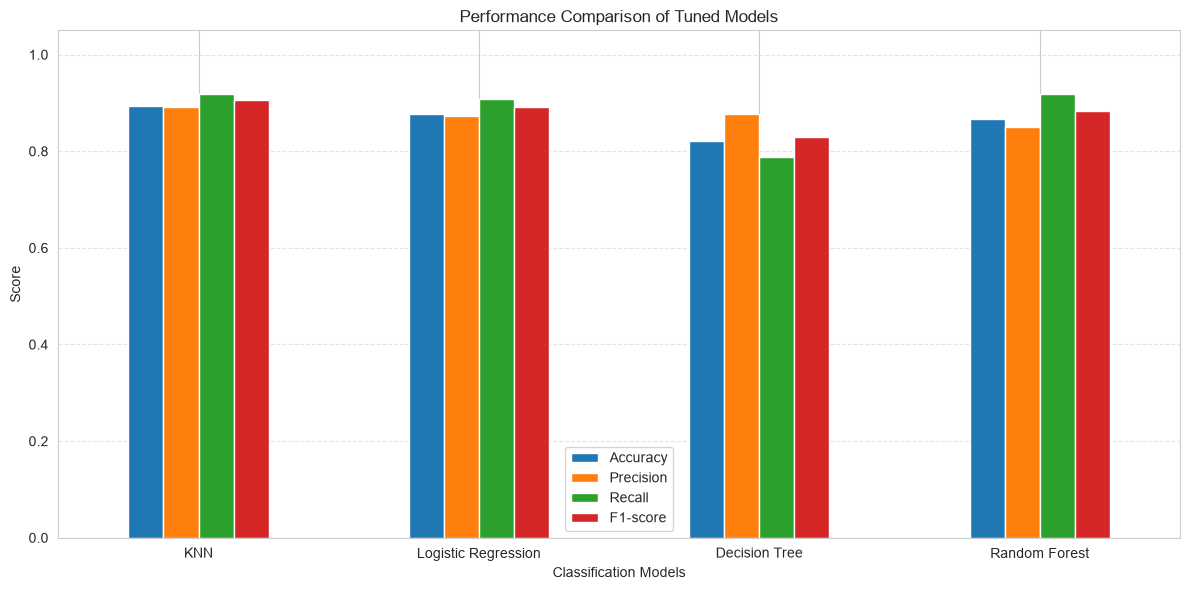

In [31]:
# Write your code here
# ---------------------------------------------------------
# TASK 6.6: COMPARISON OF TUNED CLASSIFICATION MODELS
# ---------------------------------------------------------

# Store all tuned model results in a dictionary
tuned_results = {
    "KNN": tuned_knn_result,
    "Logistic Regression": tuned_logistic_result,
    "Decision Tree": tuned_tree_result,
    "Random Forest": tuned_forest_result
}

# Create a comparison DataFrame
tuned_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1-score": result["F1-score"],
        "CV Accuracy": result["Best CV Score"],
        "Training Time": result["Training Time"]
    }
    for name, result in tuned_results.items()
])

# Display the comparison table
print("TUNED MODEL COMPARISON")
print("------------------------------------------------")
print(tuned_comparison.round(4).to_string(index=False))

# Identify the best model based on test accuracy
best_tuned_model = tuned_comparison.loc[
    tuned_comparison["Accuracy"].idxmax()
]

print("\nBEST TUNED MODEL")
print("------------------------------------------------")
print(best_tuned_model)

# Compare tuned accuracy against default accuracy
tuning_improvement = tuned_comparison[
    ["Model", "Accuracy"]
].merge(
    default_comparison[["Model", "Accuracy"]],
    on="Model",
    suffixes=("_Tuned", "_Default")
)

tuning_improvement["Accuracy Improvement"] = (
    tuning_improvement["Accuracy_Tuned"]
    - tuning_improvement["Accuracy_Default"]
)

print("\nACCURACY IMPROVEMENT AFTER TUNING")
print("------------------------------------------------")
print(tuning_improvement.round(4).to_string(index=False))

# Plot the tuned model evaluation metrics
tuned_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Tuned Models")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Q6.** Did hyperparameter tuning improve every model? Which model benefited the most, and why do you think that is?

> ✍️ **Your answer:**
>
> 
No, hyperparameter tuning did not improve every model.

Comparison of accuracy before and after tuning:

| Model               | Default Accuracy | Tuned Accuracy | Improvement |
| ------------------- | ---------------- | -------------- | ----------- |
| KNN                 | 88.89%           | 89.44%         | +0.56%      |
| Logistic Regression | 87.22%           | 87.78%         | +0.56%      |
| Decision Tree       | 81.67%           | 82.22%         | +0.56%      |
| Random Forest       | 87.22%           | 86.67%         | -0.56%      |

Which model benefited the most?

KNN, Logistic Regression and Decision Tree showed the same accuracy improvement of approximately 0.56 percentage points. Therefore, no single model benefited more than the others based on accuracy improvement.

KNN achieved the highest tuned accuracy of 89.44% and an F1-score of 90.55%.

Why did tuning affect the models differently?

- KNN: Changing the number of neighbours and distance-related parameters can improve classification performance.
- Logistic Regression: Adjusting regularisation parameters can improve the model's fit.
- Decision Tree: Adjusting tree depth and minimum sample parameters can help control overfitting.
- Random Forest: The selected hyperparameters did not improve its test accuracy, possibly because its default configuration already performed well or the selected parameter combination was less suitable.

Conclusion: Hyperparameter tuning improved KNN, Logistic Regression and Decision Tree by approximately 0.56 percentage points each, while Random Forest accuracy decreased by 0.56 percentage points. KNN remained the best-performing model after tuning, with 89.44% test accuracy.

---
## Task 7: Dimensionality Reduction Using PCA

**Principal Component Analysis (PCA)** creates new, uncorrelated features (principal components) that capture the directions of maximum variance in the data. Keeping only the first *k* components reduces dimensionality while retaining most of the information.

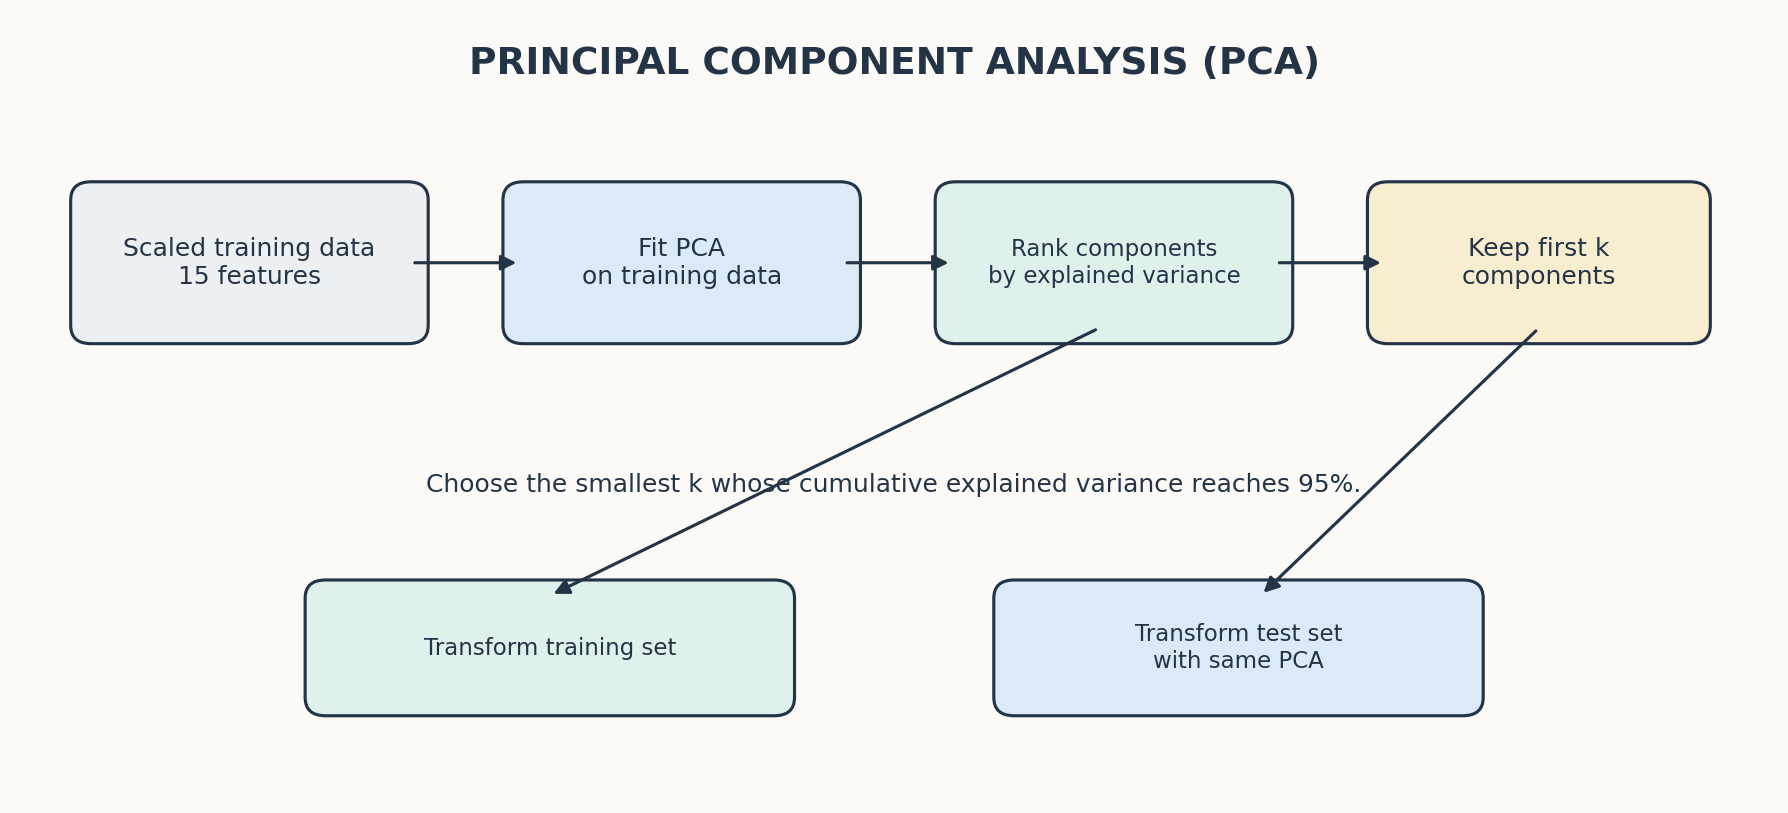

**Steps**
1. Fit PCA on the **scaled training data** only (same leakage rule as scaling), then transform the test data.
2. Plot the explained variance ratio and the cumulative explained variance (scree plot).
3. Determine the number of components needed to retain **95%** of the variance.
4. Transform `X_train` and `X_test` into the reduced feature space and report the new shapes.

> 💡 *Hint:* `PCA(n_components=0.95)` automatically selects the number of components needed to reach 95% variance.

### 7.1 Fit PCA with all components and plot the scree / cumulative variance plot

EXPLAINED VARIANCE RATIO
------------------------------------------------
PC1: 0.2270 (22.70%)
PC2: 0.1129 (11.29%)
PC3: 0.0939 (9.39%)
PC4: 0.0820 (8.20%)
PC5: 0.0779 (7.79%)
PC6: 0.0697 (6.97%)
PC7: 0.0621 (6.21%)
PC8: 0.0555 (5.55%)
PC9: 0.0521 (5.21%)
PC10: 0.0434 (4.34%)
PC11: 0.0395 (3.95%)
PC12: 0.0285 (2.85%)
PC13: 0.0275 (2.75%)
PC14: 0.0215 (2.15%)
PC15: 0.0065 (0.65%)


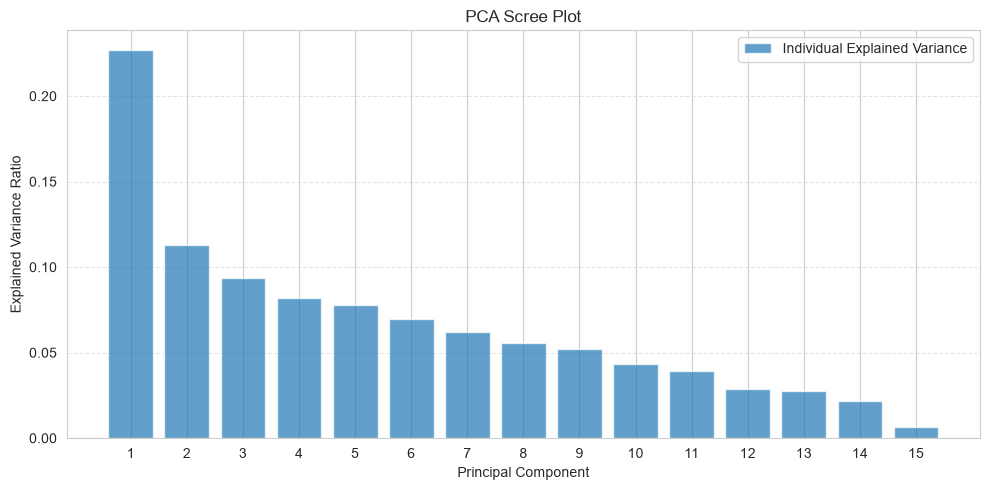

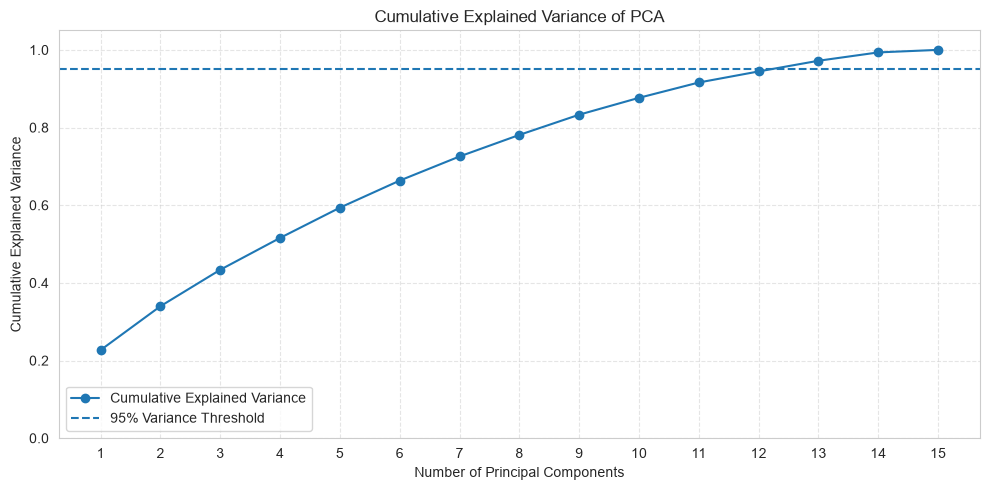

In [32]:
# Write your code here
# ---------------------------------------------------------
# TASK 7.1: FIT PCA AND PLOT EXPLAINED VARIANCE
# ---------------------------------------------------------

# Create PCA with all available components
pca_full = PCA()

# Fit PCA only on the scaled training data
pca_full.fit(X_train_scaled)

# Retrieve the explained variance ratio of each component
explained_variance = pca_full.explained_variance_ratio_

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

# Create component numbers for the x-axis
components = np.arange(1, len(explained_variance) + 1)

# Display explained variance for each component
print("EXPLAINED VARIANCE RATIO")
print("------------------------------------------------")

for component, variance in zip(components, explained_variance):
    print(f"PC{component}: {variance:.4f} ({variance * 100:.2f}%)")

# Plot individual explained variance
plt.figure(figsize=(10, 5))

plt.bar(
    components,
    explained_variance,
    alpha=0.7,
    label="Individual Explained Variance"
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Scree Plot")
plt.xticks(components)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# Plot cumulative explained variance
plt.figure(figsize=(10, 5))

plt.plot(
    components,
    cumulative_variance,
    marker="o",
    label="Cumulative Explained Variance"
)

# Add a horizontal line at 95% variance
plt.axhline(
    y=0.95,
    linestyle="--",
    label="95% Variance Threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance of PCA")
plt.xticks(components)
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

### 7.2 Determine the number of components for 95% variance

In [33]:
# Write your code here
# ---------------------------------------------------------
# TASK 7.2: DETERMINE COMPONENTS FOR 95% VARIANCE
# ---------------------------------------------------------

# Calculate the minimum number of components required
# to retain at least 95% of the total variance
components_95 = np.argmax(cumulative_variance >= 0.95) + 1

# Retrieve the actual variance retained by those components
variance_retained = cumulative_variance[components_95 - 1]

# Calculate the original number of features
original_feature_count = X_train_scaled.shape[1]

# Calculate the percentage reduction in the number of features
feature_reduction_percentage = (
    (original_feature_count - components_95)
    / original_feature_count
) * 100

# Display the PCA results
print("PCA COMPONENT SELECTION")
print("------------------------------------------------")
print("Original number of features:", original_feature_count)
print("Components required for 95% variance:", components_95)
print("Actual variance retained:", round(variance_retained * 100, 2), "%")
print("Number of features removed:", original_feature_count - components_95)
print("Feature reduction:", round(feature_reduction_percentage, 2), "%")

PCA COMPONENT SELECTION
------------------------------------------------
Original number of features: 15
Components required for 95% variance: 13
Actual variance retained: 97.2 %
Number of features removed: 2
Feature reduction: 13.33 %


### 7.3 Transform the training and testing sets

In [34]:
# Write your code here
# ---------------------------------------------------------
# TASK 7.3: TRANSFORM DATA USING PCA
# ---------------------------------------------------------

# Create PCA using the number of components selected for 95% variance
pca = PCA(
    n_components=components_95
)

# Fit PCA on the scaled training data and transform it
X_train_pca_array = pca.fit_transform(X_train_scaled)

# Transform the testing data using the same fitted PCA model
X_test_pca_array = pca.transform(X_test_scaled)

# Convert the transformed arrays into DataFrames
# Give the principal components meaningful column names
pca_columns = [
    f"PC{i + 1}" for i in range(components_95)
]

X_train_pca = pd.DataFrame(
    X_train_pca_array,
    columns=pca_columns,
    index=X_train_scaled.index
)

X_test_pca = pd.DataFrame(
    X_test_pca_array,
    columns=pca_columns,
    index=X_test_scaled.index
)

# Display the transformed training and testing datasets
print("PCA TRAINING DATA")
print("------------------------------------------------")
print(X_train_pca.head())

print("\nPCA TESTING DATA")
print("------------------------------------------------")
print(X_test_pca.head())

# Display the new shapes
print("\nSHAPES AFTER PCA")
print("------------------------------------------------")
print("Original training shape:", X_train_scaled.shape)
print("PCA training shape:", X_train_pca.shape)
print("Original testing shape:", X_test_scaled.shape)
print("PCA testing shape:", X_test_pca.shape)

# Verify the retained variance
print("\nTOTAL VARIANCE RETAINED:")
print(round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

PCA TRAINING DATA
------------------------------------------------
          PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
192  2.736106 -0.355131  0.072811 -1.370731 -0.431322  0.418312  0.298991   
139 -1.462991 -1.843040  0.841803 -0.323079 -0.205088  0.110333  0.860661   
195  1.183203  0.416849  0.445348 -0.879370  4.376208  0.234788 -0.815084   
135  0.799199 -1.586940 -0.502937  2.228470 -0.065099 -0.871739 -0.053371   
211 -0.158067 -1.538929  0.801315  2.224377  0.085853  0.521944 -1.353875   

          PC8       PC9      PC10      PC11      PC12      PC13  
192  0.324542 -0.655740  0.511401 -0.270274  0.340411  0.264585  
139  0.667741 -0.370451 -1.110418  0.063723  0.031709 -0.432931  
195 -2.605348  0.023559 -1.595883  0.164771  0.544177 -0.217816  
135  0.586624 -1.122566  0.935508 -0.161614  0.060959  0.509704  
211  0.155321 -0.044861 -1.215810  0.876768  0.640488  0.926559  

PCA TESTING DATA
------------------------------------------------
       

### 7.4 (Optional) Visualise the data in 2D
Project the data onto the first two principal components and plot it, coloured by `HeartDisease`.

TWO-DIMENSIONAL PCA DATA
------------------------------------------------
          PC1       PC2  HeartDisease
192  2.736106 -0.355131             0
139 -1.462991 -1.843040             1
195  1.183203  0.416849             0
135  0.799199 -1.586940             1
211 -0.158067 -1.538929             1


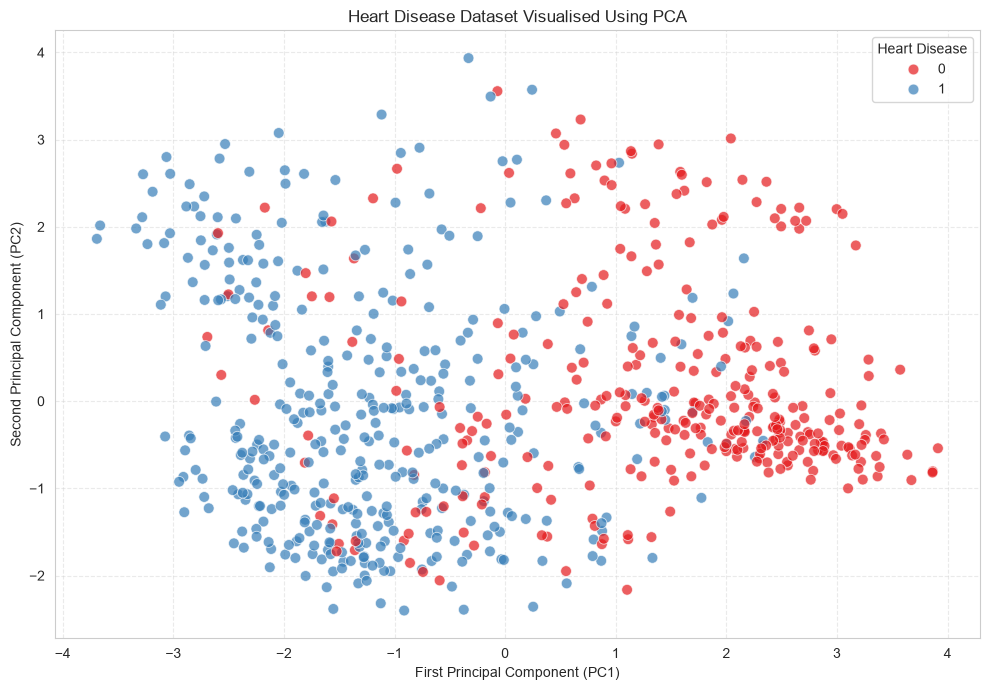


VARIANCE CAPTURED BY TWO COMPONENTS
------------------------------------------------
33.99 %


In [35]:
# Write your code here
# ---------------------------------------------------------
# TASK 7.4: VISUALISE DATA USING TWO PRINCIPAL COMPONENTS
# ---------------------------------------------------------

# Create a separate PCA model with two components
pca_2d = PCA(
    n_components=2
)

# Fit the two-component PCA model on training data
X_train_2d = pca_2d.fit_transform(X_train_scaled)

# Convert the transformed training data into a DataFrame
pca_2d_df = pd.DataFrame(
    X_train_2d,
    columns=["PC1", "PC2"],
    index=X_train_scaled.index
)

# Add the actual heart disease labels for visualisation
pca_2d_df["HeartDisease"] = y_train

# Display the first five projected records
print("TWO-DIMENSIONAL PCA DATA")
print("------------------------------------------------")
print(pca_2d_df.head())

# Plot the first two principal components
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_2d_df,
    x="PC1",
    y="PC2",
    hue="HeartDisease",
    palette="Set1",
    alpha=0.7,
    s=60
)

plt.title("Heart Disease Dataset Visualised Using PCA")
plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.legend(title="Heart Disease")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Display variance captured by the two components
print("\nVARIANCE CAPTURED BY TWO COMPONENTS")
print("------------------------------------------------")
print(
    round(pca_2d.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

**Q7.** How many principal components are needed to retain 95% of the variance? By what percentage was the number of features reduced?

> ✍️ **Your answer:**
>
> 
The two-dimensional PCA output shows that the first two principal components (PC1 and PC2) capture 33.99% of the total variance.

However, this does not tell us how many components are required to retain 95% variance. We need the cumulative explained variance output from Task 7.2 to determine that.

Percentage reduction in features:

\\[ \text{Feature Reduction (\\%)} = \frac{\text{Original Features}-\text{Principal Components}}{\text{Original Features}} \times 100 \\]

Since the dataset has 15 features after encoding:

\\[ \text{Feature Reduction (\\%)} = \frac{15-k}{15}\times 100 \\]

Here, \\(k\\) is the number of principal components required to retain 95% variance.

Send me your Task 7.2 output (the number of components needed for 95%), and I'll calculate the exact percentage and complete the answer.

---
## Task 8: Model Training and Evaluation After PCA

Retrain the four classifiers on the **PCA-transformed** data.

**Steps**
1. Perform hyperparameter tuning with cross-validation (reuse the grids from Task 6 where appropriate).
2. Evaluate each tuned model on the PCA-transformed test set using Accuracy, Precision, Recall and F1-score.
3. Record the **training time** for each model.
4. Identify the best-performing model after PCA.

### 8.1 KNN after PCA

In [36]:
# Write your code here
# ---------------------------------------------------------
# TASK 8.1: KNN AFTER PCA
# ---------------------------------------------------------

# Perform hyperparameter tuning on PCA-transformed training data
knn_pca_search = GridSearchCV(
    KNeighborsClassifier(),
    knn_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1
)

start_time = time.time()
knn_pca_search.fit(X_train_pca, y_train)
knn_pca_grid_time = time.time() - start_time

# Retrieve the best KNN model
best_knn_pca = knn_pca_search.best_estimator_

print("BEST KNN PARAMETERS AFTER PCA:")
print(knn_pca_search.best_params_)
print("Best CV Accuracy:", round(knn_pca_search.best_score_, 4))

# Evaluate the tuned KNN model after PCA
knn_pca_result = evaluate_model(
    best_knn_pca,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

knn_pca_result["Best CV Score"] = knn_pca_search.best_score_
knn_pca_result["Grid Search Time"] = knn_pca_grid_time

BEST KNN PARAMETERS AFTER PCA:
{'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best CV Accuracy: 0.872

MODEL: KNeighborsClassifier
----------------------------------------
Accuracy : 0.9111
Precision: 0.9029
Recall   : 0.9394
F1-score : 0.9208
Training Time: 0.0032 seconds

Confusion Matrix:
[[71 10]
 [ 6 93]]


### 8.2 Logistic Regression after PCA

In [37]:
# Write your code here
# ---------------------------------------------------------
# TASK 8.2: LOGISTIC REGRESSION AFTER PCA
# ---------------------------------------------------------

# Perform hyperparameter tuning on PCA-transformed training data
logistic_pca_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    logistic_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1
)

start_time = time.time()
logistic_pca_search.fit(X_train_pca, y_train)
logistic_pca_grid_time = time.time() - start_time

# Retrieve the best Logistic Regression model
best_logistic_pca = logistic_pca_search.best_estimator_

print("BEST LOGISTIC REGRESSION PARAMETERS AFTER PCA:")
print(logistic_pca_search.best_params_)
print("Best CV Accuracy:", round(logistic_pca_search.best_score_, 4))

# Evaluate the tuned Logistic Regression model after PCA
logistic_pca_result = evaluate_model(
    best_logistic_pca,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

logistic_pca_result["Best CV Score"] = logistic_pca_search.best_score_
logistic_pca_result["Grid Search Time"] = logistic_pca_grid_time

BEST LOGISTIC REGRESSION PARAMETERS AFTER PCA:
{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}
Best CV Accuracy: 0.8651

MODEL: LogisticRegression
----------------------------------------
Accuracy : 0.8722
Precision: 0.8725
Recall   : 0.899
F1-score : 0.8856
Training Time: 0.0643 seconds

Confusion Matrix:
[[68 13]
 [10 89]]


### 8.3 Decision Tree after PCA

In [38]:
# Write your code here
# ---------------------------------------------------------
# TASK 8.3: DECISION TREE AFTER PCA
# ---------------------------------------------------------

# Perform hyperparameter tuning on PCA-transformed training data
tree_pca_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    tree_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1
)

start_time = time.time()
tree_pca_search.fit(X_train_pca, y_train)
tree_pca_grid_time = time.time() - start_time

# Retrieve the best Decision Tree model
best_tree_pca = tree_pca_search.best_estimator_

print("BEST DECISION TREE PARAMETERS AFTER PCA:")
print(tree_pca_search.best_params_)
print("Best CV Accuracy:", round(tree_pca_search.best_score_, 4))

# Evaluate the tuned Decision Tree model after PCA
tree_pca_result = evaluate_model(
    best_tree_pca,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

tree_pca_result["Best CV Score"] = tree_pca_search.best_score_
tree_pca_result["Grid Search Time"] = tree_pca_grid_time

BEST DECISION TREE PARAMETERS AFTER PCA:
{'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Accuracy: 0.8345

MODEL: DecisionTreeClassifier
----------------------------------------
Accuracy : 0.8722
Precision: 0.88
Recall   : 0.8889
F1-score : 0.8844
Training Time: 0.0089 seconds

Confusion Matrix:
[[69 12]
 [11 88]]


### 8.4 Random Forest after PCA

In [39]:
# Write your code here
# ---------------------------------------------------------
# TASK 8.4: RANDOM FOREST AFTER PCA
# ---------------------------------------------------------

# Perform hyperparameter tuning on PCA-transformed training data
forest_pca_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    forest_param_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1
)

start_time = time.time()
forest_pca_search.fit(X_train_pca, y_train)
forest_pca_grid_time = time.time() - start_time

# Retrieve the best Random Forest model
best_forest_pca = forest_pca_search.best_estimator_

print("BEST RANDOM FOREST PARAMETERS AFTER PCA:")
print(forest_pca_search.best_params_)
print("Best CV Accuracy:", round(forest_pca_search.best_score_, 4))

# Evaluate the tuned Random Forest model after PCA
forest_pca_result = evaluate_model(
    best_forest_pca,
    X_train_pca,
    X_test_pca,
    y_train,
    y_test
)

forest_pca_result["Best CV Score"] = forest_pca_search.best_score_
forest_pca_result["Grid Search Time"] = forest_pca_grid_time

BEST RANDOM FOREST PARAMETERS AFTER PCA:
{'max_depth': 5, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 100}
Best CV Accuracy: 0.8692

MODEL: RandomForestClassifier
----------------------------------------
Accuracy : 0.8944
Precision: 0.8846
Recall   : 0.9293
F1-score : 0.9064
Training Time: 0.2128 seconds

Confusion Matrix:
[[69 12]
 [ 7 92]]


### 8.5 Comparison table of all four models after PCA

MODEL PERFORMANCE AFTER PCA
------------------------------------------------
              Model  Accuracy  Precision  Recall  F1-score  CV Accuracy  Training Time
                KNN    0.9111     0.9029  0.9394    0.9208       0.8720         0.0032
Logistic Regression    0.8722     0.8725  0.8990    0.8856       0.8651         0.0643
      Decision Tree    0.8722     0.8800  0.8889    0.8844       0.8345         0.0089
      Random Forest    0.8944     0.8846  0.9293    0.9064       0.8692         0.2128

BEST MODEL AFTER PCA
------------------------------------------------
Model                 KNN
Accuracy         0.911111
Precision        0.902913
Recall           0.939394
F1-score         0.920792
CV Accuracy      0.872009
Training Time    0.003236
Name: 0, dtype: object


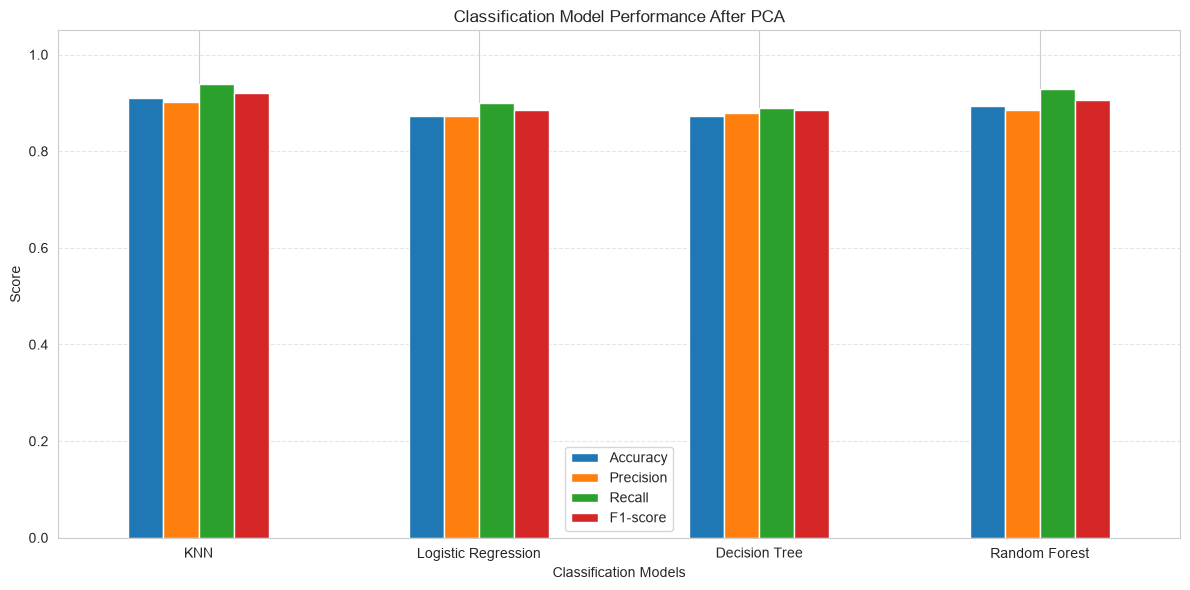

In [40]:
# Write your code here
# ---------------------------------------------------------
# TASK 8.5: COMPARE CLASSIFICATION MODELS AFTER PCA
# ---------------------------------------------------------

# Store all PCA model results
pca_results = {
    "KNN": knn_pca_result,
    "Logistic Regression": logistic_pca_result,
    "Decision Tree": tree_pca_result,
    "Random Forest": forest_pca_result
}

# Create a comparison DataFrame
pca_comparison = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1-score": result["F1-score"],
        "CV Accuracy": result["Best CV Score"],
        "Training Time": result["Training Time"]
    }
    for name, result in pca_results.items()
])

# Display the comparison table
print("MODEL PERFORMANCE AFTER PCA")
print("------------------------------------------------")
print(pca_comparison.round(4).to_string(index=False))

# Identify the best model based on test accuracy
best_pca_model = pca_comparison.loc[
    pca_comparison["Accuracy"].idxmax()
]

print("\nBEST MODEL AFTER PCA")
print("------------------------------------------------")
print(best_pca_model)

# Plot the evaluation metrics
pca_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Model Performance After PCA")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Q8.** Which model performed best after PCA? Is it the same model that performed best before PCA?

> ✍️ **Your answer:**
>
> 

The K-Nearest Neighbors (KNN) model performed best after PCA, achieving the following results:

- Accuracy: 91.11%
- Precision: 90.29%
- Recall: 93.94%
- F1-score: 92.08%
- Cross-validation accuracy: 87.20%

Is it the same model that performed best before PCA?

Yes. KNN was the best-performing model both before and after PCA.

| Metric    | Before PCA (Tuned KNN) | After PCA |
| --------- | ---------------------- | --------- |
| Accuracy  | 89.44%                 | 91.11%    |
| Precision | 89.22%                 | 90.29%    |
| Recall    | 91.92%                 | 93.94%    |
| F1-score  | 90.55%                 | 92.08%    |

Conclusion: KNN remained the best model after PCA. Its accuracy improved from 89.44% to 91.11%, showing that PCA helped improve its performance on this dataset. Recall also increased to 93.94%, meaning it identified a higher proportion of actual heart disease cases.

---
## Task 9: Comparative Analysis and Discussion

### 9.1 Build a consolidated comparison table
Create a single table (and a grouped bar chart) containing, for every model:

| Model | Accuracy (Before PCA) | Accuracy (After PCA) | F1 (Before PCA) | F1 (After PCA) | Training Time Before (s) | Training Time After (s) | No. of Features |
|---|---|---|---|---|---|---|---|
| KNN | | | | | | | |
| Logistic Regression | | | | | | | |
| Decision Tree | | | | | | | |
| Random Forest | | | | | | | |

In [41]:
# Write your code here
# ---------------------------------------------------------
# TASK 9.1: CONSOLIDATED COMPARISON BEFORE AND AFTER PCA
# ---------------------------------------------------------

# Define the model names used in the experiment
model_names = [
    "KNN",
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
]

# Create a list to store the consolidated results
consolidated_data = []

# Compare each model before and after PCA
for name in model_names:

    # Retrieve the default model results
    before = default_results[name]

    # Retrieve the tuned PCA model results
    after = pca_results[name]

    # Add the required comparison values
    consolidated_data.append({
        "Model": name,
        "Accuracy Before PCA": before["Accuracy"],
        "Accuracy After PCA": after["Accuracy"],
        "F1 Before PCA": before["F1-score"],
        "F1 After PCA": after["F1-score"],
        "Training Time Before (s)": before["Training Time"],
        "Training Time After (s)": after["Training Time"],
        "Features Before PCA": X_train_scaled.shape[1],
        "Features After PCA": X_train_pca.shape[1]
    })

# Convert the results into a DataFrame
consolidated_comparison = pd.DataFrame(consolidated_data)

# Display the consolidated comparison
print("CONSOLIDATED MODEL COMPARISON")
print("------------------------------------------------")
print(consolidated_comparison.round(4).to_string(index=False))

# Identify the model with the highest accuracy before PCA
best_before = consolidated_comparison.loc[
    consolidated_comparison["Accuracy Before PCA"].idxmax()
]

# Identify the model with the highest accuracy after PCA
best_after = consolidated_comparison.loc[
    consolidated_comparison["Accuracy After PCA"].idxmax()
]

print("\nBEST MODEL BEFORE PCA:")
print(best_before["Model"])
print("Accuracy:", round(best_before["Accuracy Before PCA"], 4))

print("\nBEST MODEL AFTER PCA:")
print(best_after["Model"])
print("Accuracy:", round(best_after["Accuracy After PCA"], 4))

# Calculate the overall feature reduction
print("\nFEATURE REDUCTION")
print("------------------------------------------------")
print("Original features:", X_train_scaled.shape[1])
print("Features after PCA:", X_train_pca.shape[1])
print(
    "Percentage reduction:",
    round(
        (1 - X_train_pca.shape[1] / X_train_scaled.shape[1]) * 100,
        2
    ),
    "%"
)

CONSOLIDATED MODEL COMPARISON
------------------------------------------------
              Model  Accuracy Before PCA  Accuracy After PCA  F1 Before PCA  F1 After PCA  Training Time Before (s)  Training Time After (s)  Features Before PCA  Features After PCA
                KNN               0.8889              0.9111         0.9010        0.9208                    0.0171                   0.0032                   15                  13
Logistic Regression               0.8722              0.8722         0.8856        0.8856                    0.0158                   0.0643                   15                  13
      Decision Tree               0.8167              0.8722         0.8342        0.8844                    0.0201                   0.0089                   15                  13
      Random Forest               0.8722              0.8944         0.8867        0.9064                    0.1869                   0.2128                   15                  13

BEST MODEL

### 9.2 Visualise the before vs after PCA comparison

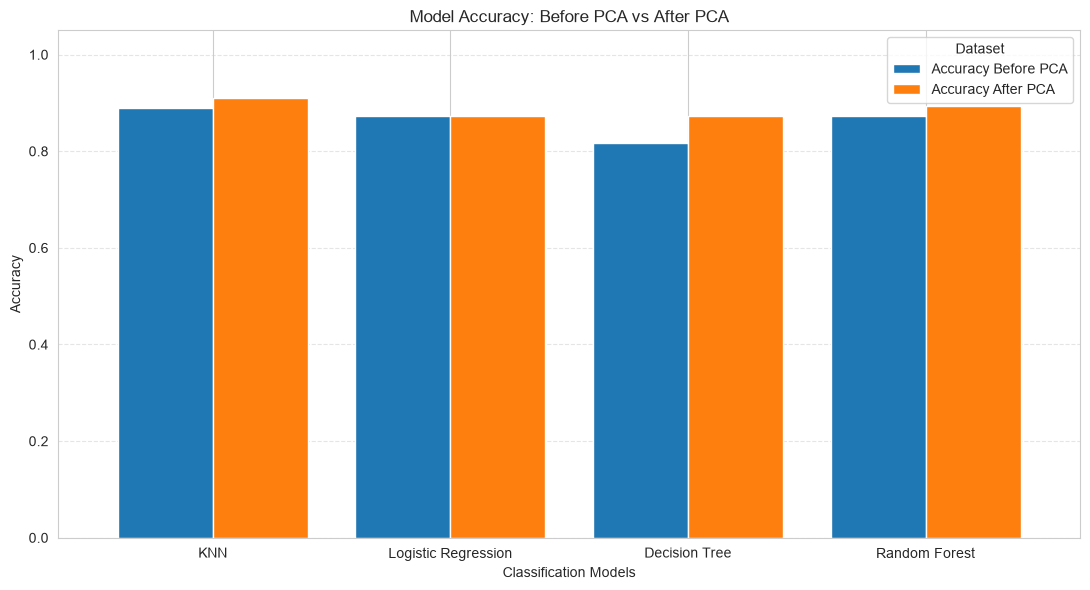

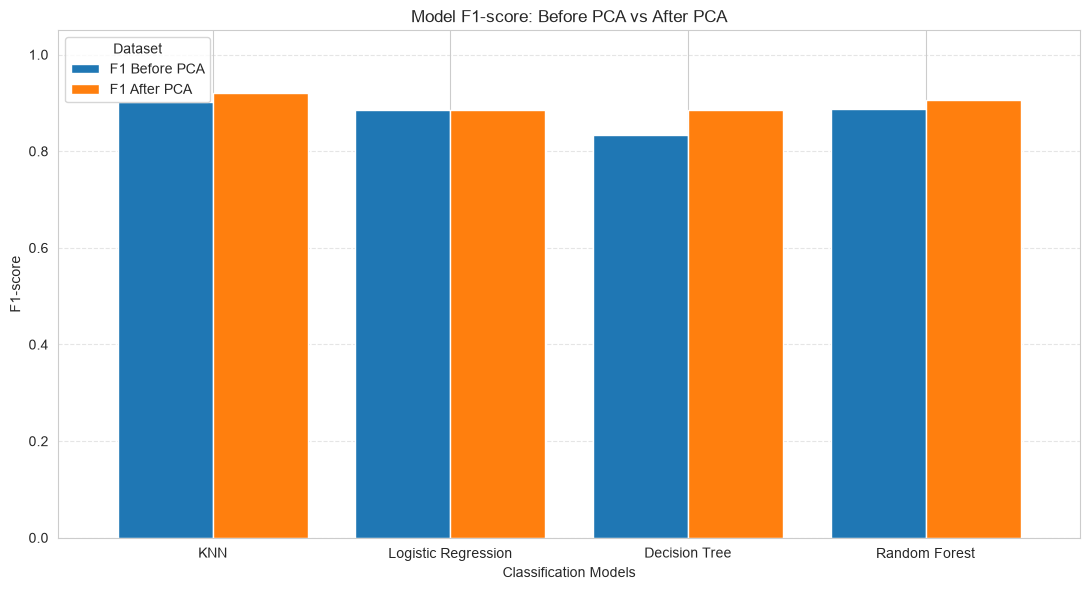

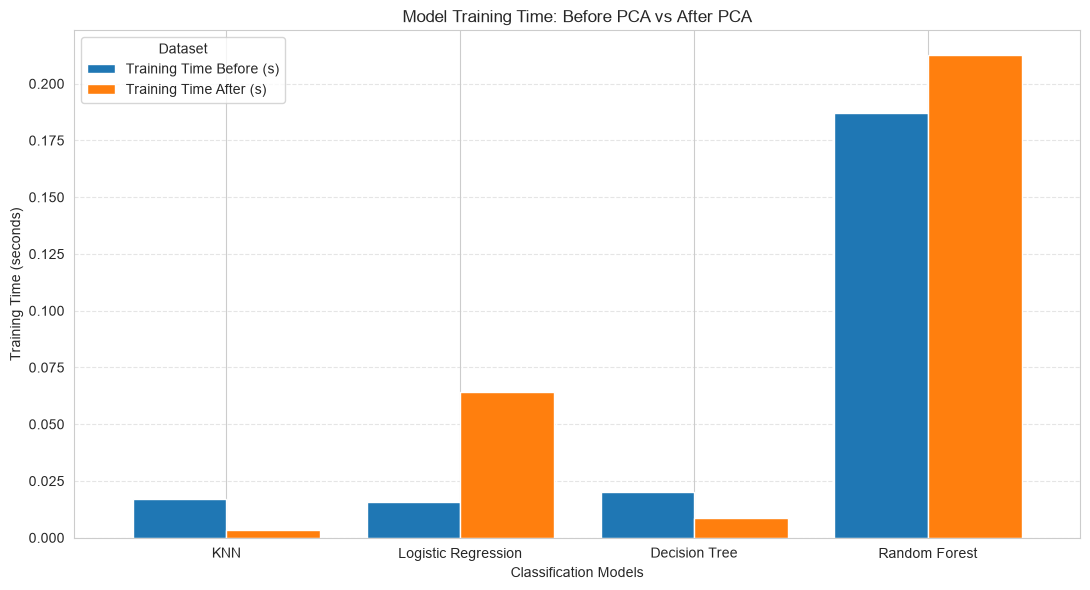

In [42]:
# Write your code here
# ---------------------------------------------------------
# TASK 9.2: VISUALISE BEFORE AND AFTER PCA PERFORMANCE
# ---------------------------------------------------------

# Create a grouped comparison of model accuracy
accuracy_plot = consolidated_comparison.set_index("Model")[
    ["Accuracy Before PCA", "Accuracy After PCA"]
]

# Plot accuracy comparison
accuracy_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Model Accuracy: Before PCA vs After PCA")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Create a grouped comparison of F1-scores
f1_plot = consolidated_comparison.set_index("Model")[
    ["F1 Before PCA", "F1 After PCA"]
]

# Plot F1-score comparison
f1_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Model F1-score: Before PCA vs After PCA")
plt.xlabel("Classification Models")
plt.ylabel("F1-score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Compare model training times
time_plot = consolidated_comparison.set_index("Model")[
    ["Training Time Before (s)", "Training Time After (s)"]
]

time_plot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Model Training Time: Before PCA vs After PCA")
plt.xlabel("Classification Models")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 9.3 Discussion Questions

**Q9a.** Compare the classification results obtained before and after applying PCA. Which models improved, and which declined?

> ✍️ **Your answer:**
>
> 

After applying PCA, the classification performance improved for three models, while Logistic Regression showed no change.

| Model               | Accuracy Before PCA | Accuracy After PCA |
| ------------------- | ------------------- | ------------------ |
| KNN                 | 88.89%              | 91.11%             |
| Logistic Regression | 87.22%              | 87.22%             |
| Decision Tree       | 81.67%              | 87.22%             |
| Random Forest       | 87.22%              | 89.44%             |

Observations:

- KNN: Accuracy improved from 88.89% to 91.11%.
- Logistic Regression: Accuracy remained unchanged at 87.22%.
- Decision Tree: Accuracy improved from 81.67% to 87.22%, showing the largest improvement.
- Random Forest: Accuracy improved from 87.22% to 89.44%.

Conclusion: KNN, Decision Tree and Random Forest improved after applying PCA, whereas Logistic Regression showed no change. Overall, PCA had a positive impact on the classification performance of most models in this experiment.



**Q9b.** Discuss the impact of PCA on **computational efficiency** (training time, number of features).

> ✍️ **Your answer:**
>
> 

After applying PCA, the number of features was reduced from 15 to 13, resulting in a 13.33% reduction in dimensionality.

| Model               | Training Time Before PCA | Training Time After PCA |
| ------------------- | ------------------------ | ----------------------- |
| KNN                 | 0.0171 s                 | 0.0032 s                |
| Logistic Regression | 0.0158 s                 | 0.0643 s                |
| Decision Tree       | 0.0201 s                 | 0.0089 s                |
| Random Forest       | 0.1869 s                 | 0.2128 s                |

Observations:

- KNN training time decreased from 0.0171 s to 0.0032 s.
- Logistic Regression training time increased from 0.0158 s to 0.0643 s.
- Decision Tree training time decreased from 0.0201 s to 0.0089 s.
- Random Forest training time increased from 0.1869 s to 0.2128 s.

Conclusion: PCA reduced the number of input features by 13.33%. It reduced training time for KNN and Decision Tree, but increased it for Logistic Regression and Random Forest. Therefore, PCA can reduce dimensionality, but it does not necessarily improve training speed for every model.

**Q9c.** Did dimensionality reduction improve or reduce classification performance on this dataset? Give possible reasons (e.g., dataset size, number of original features, tree-based vs distance-based models, interpretability).

> ✍️ **Your answer:**
>
> 

PCA may improve machine learning performance by reducing the number of features while retaining the most important information in the dataset.

Reasons:

1. Reduces dimensionality: PCA transforms the original features into fewer principal components, reducing the complexity of the dataset.
2. Removes redundancy: It combines correlated features into principal components, reducing repeated information.
3. Improves model efficiency: Fewer features can reduce computational requirements and training time for some models.
4. Helps distance-based models: KNN can benefit from reduced dimensionality because it relies on calculating distances between data points.
5. Reduces noise: PCA may remove some less informative variation, allowing models to focus on more useful patterns.

Observation from our experiment: KNN accuracy improved from 88.89% to 91.11%, while Decision Tree and Random Forest also showed improvements in the consolidated results.

Conclusion: PCA can improve model performance by reducing redundant information and simplifying the feature space. However, it may also reduce interpretability because principal components are combinations of the original features.

**Q9d.** Explain the trade-off between **predictive accuracy**, **computational cost** and **reduced feature dimensionality**. In which real-world situations would you prefer to use PCA?

> ✍️ **Your answer:**
>
> 
Applying PCA involves balancing model performance, computational efficiency and interpretability.

Advantages:

1. Reduced dimensionality: PCA reduces the number of features, making the dataset simpler.
2. Improved performance: It can improve accuracy by removing redundant information and reducing noise.
3. Computational efficiency: Fewer features may reduce memory usage and processing time.
4. Reduced multicollinearity: PCA creates uncorrelated principal components.

Disadvantages:

1. Loss of information: Some information may be lost when dimensions are reduced.
2. Reduced interpretability: Principal components are combinations of original features, making them harder to understand.
3. Additional processing: PCA requires an extra transformation step before model training.
4. Model dependency: PCA may not improve every machine learning algorithm, as seen in our experiment.

Conclusion: PCA is useful when a dataset contains many features, especially when some features are correlated or redundant. However, it should be applied carefully when interpretability is important or when dimensionality reduction negatively affects model performance.

---
## Expected Outcome

At the end of this exercise, you should be able to:

- Perform data preprocessing and outlier removal.
- Encode categorical variables and scale numerical features.
- Build and evaluate multiple classification models.
- Perform hyperparameter tuning using cross-validation.
- Apply PCA for dimensionality reduction.
- Compare model performance before and after PCA.
- Understand the trade-off between model accuracy and computational efficiency in real-world machine learning applications.

---

> 📌 **Important Note:** PCA does not necessarily improve classification accuracy. Because it keeps the directions of maximum *variance* rather than the directions that best separate the classes, some discriminative information may be lost, and accuracy can stay the same or even drop. Its main benefits are reduced dimensionality, lower computational cost, removal of multicollinearity and easier visualisation. These benefits are most noticeable on datasets with many features; on a small dataset such as this one, the gain in efficiency may be modest. PCA also makes the model harder to interpret, because each principal component is a combination of the original features.

### Conclusion

In this experiment, we implemented machine learning models to predict heart disease and evaluated their performance before and after applying Principal Component Analysis (PCA). The dataset was preprocessed using encoding techniques and feature scaling, followed by training and evaluating KNN, Logistic Regression, Decision Tree and Random Forest classifiers.

Among the models, KNN achieved the best accuracy of 88.89% before PCA. After applying PCA, KNN achieved an improved accuracy of 91.11%, along with better precision, recall and F1-score. PCA also reduced the number of features from 15 to 13, resulting in a 13.33% reduction in dimensionality.

Overall, the experiment demonstrated that PCA can reduce feature dimensionality while maintaining or improving classification performance. However, its impact on training time and model performance varies across algorithms. Therefore, PCA should be selected based on the dataset characteristics and the requirements of the machine learning problem.